# Kiểm định giả thuyết hai mẫu độc lập trên NSL-KDD

Notebook này so sánh nhóm **Normal** và **Attack** trên tập `train_clean.csv` gốc, chưa SMOTE hay chuẩn hóa. Tập test được giữ riêng cho Machine Learning. Ba câu hỏi nghiên cứu là: (RQ1) `srv_serror_rate`, (RQ2) `srv_rerror_rate`, và (RQ3) `count`.

Phân tích kiểm định sự khác biệt trung bình, không huấn luyện mô hình và không suy ra quan hệ nhân quả.

## Giả thuyết và phương pháp

Với từng biến $X$, đặt $H_0: \mu_N=\mu_A$ và $H_1: \mu_N\ne\mu_A$, mức ý nghĩa $\alpha=0.05$. Kiểm định chính là Welch hai mẫu độc lập:

$$t=\frac{\bar X_N-\bar X_A}{\sqrt{\frac{s_N^2}{n_N}+\frac{s_A^2}{n_A}}},$$

với bậc tự do Welch--Satterthwaite

$$\nu=\frac{\left(\frac{s_N^2}{n_N}+\frac{s_A^2}{n_A}\right)^2}{\frac{(s_N^2/n_N)^2}{n_N-1}+\frac{(s_A^2/n_A)^2}{n_A-1}}.$$

Welch được chọn trước khi xem kết quả vì không buộc hai phương sai bằng nhau. P-value là xác suất quan sát thống kê ít nhất cực đoan như dữ liệu nếu $H_0$ đúng; nó không phải xác suất $H_0$ đúng. Ba p-value chính được hiệu chỉnh Holm. Các CI 95% báo cáo cho từng RQ là khoảng riêng lẻ, không tự động bảo đảm độ bao phủ đồng thời 95% cho cả ba RQ. Bác bỏ $H_0$ không chứng minh nguyên nhân hay khả năng dự đoán tốt.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
from two_sample_utils import FEATURES, run_analysis

pd.set_option('display.max_columns', 50)
tables = run_analysis(create_plots=True)
display(tables['data_validation'])

,check,value,status
0,source_rows,125973,PASS
1,duplicate_on_analysis_columns_not_removed,122515,INFO
2,attack_category_domain,"DoS, Normal, Probe, R2L, U2R",PASS
3,label_binary_domain,"0, 1",PASS
4,normal_attack_mapping,True,PASS
5,srv_serror_rate_missing,0,PASS
6,srv_serror_rate_nonfinite,0,PASS
7,srv_rerror_rate_missing,0,PASS
8,srv_rerror_rate_nonfinite,0,PASS
9,count_missing,0,PASS


## Thống kê mô tả và khoảng tin cậy 95%

Khoảng tin cậy trong bảng là CI của **trung bình từng nhóm**, khác với CI của chênh lệch hai trung bình ở kết quả Welch. Các tỷ lệ bằng 0/1 được báo cáo vì hai biến rate tập trung mạnh tại biên.

In [2]:
cols = ['rq','feature','group','n','mean','median','std','variance','q1','q3','zero_proportion','one_proportion','skewness','mean_ci95_low','mean_ci95_high']
display(tables['descriptive_statistics'][cols])

,rq,feature,group,n,mean,median,std,variance,q1,q3,zero_proportion,one_proportion,skewness,mean_ci95_low,mean_ci95_high
0,RQ1,srv_serror_rate,Normal,67343,0.012083,0.0,0.086426,0.007469,0.0,0.0,0.965460,0.004885,9.169199,0.011431,0.012736
1,RQ1,srv_serror_rate,Attack,58630,0.593072,1.0,0.490234,0.240329,0.0,1.0,0.404861,0.589203,-0.379688,0.589104,0.597040
2,RQ2,srv_rerror_rate,Normal,67343,0.044629,0.0,0.202264,0.040911,0.0,0.0,0.946869,0.040761,4.426216,0.043101,0.046157
3,RQ2,srv_rerror_rate,Attack,58630,0.209114,0.0,0.404487,0.163609,0.0,0.0,0.784615,0.206072,1.434092,0.205840,0.212388
4,RQ3,count,Normal,67343,22.517945,4.0,54.026086,2918.817975,1.0,14.0,0.000148,NaN,3.877569,22.109896,22.925995
5,RQ3,count,Attack,58630,154.849991,138.0,124.334483,15459.063666,40.0,241.0,0.000051,NaN,0.746983,153.843550,155.856433


## Kiểm tra giả định

Brown--Forsythe đánh giá đồng nhất phương sai nhưng không được dùng như quy tắc tự động duy nhất. Q--Q plot, skewness, khối xác suất tại biên, ngoại lệ, cỡ mẫu và tỷ số phương sai được xem đồng thời. Shapiro chỉ chạy trên tối đa 5.000 quan sát/nhóm như chẩn đoán bổ sung, không quyết định lựa chọn kiểm định. Không có session/host ID nên tính độc lập không thể kiểm chứng đầy đủ; đây là giới hạn suy luận quan trọng.

In [3]:
display(tables['assumption_checks'])

,rq,feature,n_normal,n_attack,n_ratio_max_min,variance_normal,variance_attack,variance_ratio_max_min,brown_forsythe_statistic,brown_forsythe_p_value,independence_verifiable,independence_warning,skewness_normal,iqr_outlier_proportion_normal,shapiro_sample_n_normal,shapiro_statistic_normal,shapiro_p_value_normal,skewness_attack,iqr_outlier_proportion_attack,shapiro_sample_n_attack,shapiro_statistic_attack,shapiro_p_value_attack,method_warning,brown_forsythe_p_display
0,RQ1,srv_serror_rate,67343,58630,1.14861,0.007469,0.240329,32.174969,42179.954446,0.0,False,Không có session/host ID để kiểm chứng độc lập...,9.169199,0.034540,5000,0.122140,8.599954e-93,-0.379688,0.000000,5000,0.624982,4.711581e-74,Biến tỷ lệ có khối xác suất tại biên; Welch su...,<1e-300
1,RQ2,srv_rerror_rate,67343,58630,1.14861,0.040911,0.163609,3.999170,8651.409358,0.0,False,Không có session/host ID để kiểm chứng độc lập...,4.426216,0.053131,5000,0.210077,2.383878e-90,1.434092,0.215385,5000,0.503786,5.515791e-80,Biến tỷ lệ có khối xác suất tại biên; Welch su...,<1e-300
2,RQ3,count,67343,58630,1.14861,2918.817975,15459.063666,5.296344,46458.653049,0.0,False,Không có session/host ID để kiểm chứng độc lập...,3.877569,0.118691,5000,0.428852,4.724812e-83,0.746983,0.000000,5000,0.916929,3.854365e-46,Biến đếm lệch và có ngoại lệ; dùng Welch nhờ c...,<1e-300


## Kết quả Welch, hiệu chỉnh Holm và kích thước ảnh hưởng

Chênh lệch được định nghĩa là $\bar X_{Normal}-\bar X_{Attack}$. Hedges $g$ dùng SD gộp và được xem là kích thước ảnh hưởng mô tả; CI của $g$ là xấp xỉ chuẩn. Diễn giải thực tiễn ưu tiên chênh lệch và CI trên đơn vị gốc.

In [4]:
result_cols = ['rq','feature','n_normal','n_attack','mean_normal','mean_attack','mean_difference','ci95_low','ci95_high','t_statistic','df','p_value_display','holm_p_display','reject_h0_holm']
display(tables['two_sample_results'][result_cols])
display(tables['effect_sizes'])

,rq,feature,n_normal,n_attack,mean_normal,mean_attack,mean_difference,ci95_low,ci95_high,t_statistic,df,p_value_display,holm_p_display,reject_h0_holm
0,RQ1,srv_serror_rate,67343,58630,0.012083,0.593072,-0.580988,-0.585010,-0.576967,-283.156578,61805.395685,<1e-300,<1e-300,True
1,RQ2,srv_rerror_rate,67343,58630,0.044629,0.209114,-0.164485,-0.168098,-0.160872,-89.230223,83489.743411,<1e-300,<1e-300,True
2,RQ3,count,67343,58630,22.517945,154.849991,-132.332046,-133.418057,-131.246036,-238.828335,77661.212334,<1e-300,<1e-300,True


,rq,feature,cohen_d,hedges_g,hedges_g_ci95_low_approx,hedges_g_ci95_high_approx,effect_ci_note
0,RQ1,srv_serror_rate,-1.706973,-1.706963,-1.719885,-1.694040,Normal approximation; descriptive pooled-SD ef...
1,RQ2,srv_rerror_rate,-0.525383,-0.525380,-0.536639,-0.514120,Normal approximation; descriptive pooled-SD ef...
2,RQ3,count,-1.414264,-1.414256,-1.426628,-1.401884,Normal approximation; descriptive pooled-SD ef...


## Trả lời từng câu hỏi nghiên cứu

Mỗi phần dưới đây ghép câu hỏi, mô tả, giả định, kiểm định, CI và effect size. Kết luận dựa trên p hiệu chỉnh Holm và phải đọc cùng cảnh báo về phân phối/tính độc lập.

In [5]:
for rq, cfg in FEATURES.items():
    display(Markdown(f"### {rq} — `{cfg['feature']}`\n\n**Câu hỏi:** {cfg['question']}\n\n$H_0: \\mu_N=\\mu_A$; $H_1: \\mu_N\\ne\\mu_A$."))
    display(tables['descriptive_statistics'].query('rq == @rq')[cols])
    display(tables['assumption_checks'].query('rq == @rq'))
    display(tables['two_sample_results'].query('rq == @rq')[result_cols])
    display(tables['effect_sizes'].query('rq == @rq'))

### RQ1 — `srv_serror_rate`

**Câu hỏi:** Tỷ lệ lỗi SYN trung bình có khác biệt giữa Normal và Attack hay không?

$H_0: \mu_N=\mu_A$; $H_1: \mu_N\ne\mu_A$.

,rq,feature,group,n,mean,median,std,variance,q1,q3,zero_proportion,one_proportion,skewness,mean_ci95_low,mean_ci95_high
0,RQ1,srv_serror_rate,Normal,67343,0.012083,0.0,0.086426,0.007469,0.0,0.0,0.965460,0.004885,9.169199,0.011431,0.012736
1,RQ1,srv_serror_rate,Attack,58630,0.593072,1.0,0.490234,0.240329,0.0,1.0,0.404861,0.589203,-0.379688,0.589104,0.597040


,rq,feature,n_normal,n_attack,n_ratio_max_min,variance_normal,variance_attack,variance_ratio_max_min,brown_forsythe_statistic,brown_forsythe_p_value,independence_verifiable,independence_warning,skewness_normal,iqr_outlier_proportion_normal,shapiro_sample_n_normal,shapiro_statistic_normal,shapiro_p_value_normal,skewness_attack,iqr_outlier_proportion_attack,shapiro_sample_n_attack,shapiro_statistic_attack,shapiro_p_value_attack,method_warning,brown_forsythe_p_display
0,RQ1,srv_serror_rate,67343,58630,1.14861,0.007469,0.240329,32.174969,42179.954446,0.0,False,Không có session/host ID để kiểm chứng độc lập...,9.169199,0.03454,5000,0.12214,8.599954e-93,-0.379688,0.0,5000,0.624982,4.711581e-74,Biến tỷ lệ có khối xác suất tại biên; Welch su...,<1e-300


,rq,feature,n_normal,n_attack,mean_normal,mean_attack,mean_difference,ci95_low,ci95_high,t_statistic,df,p_value_display,holm_p_display,reject_h0_holm
0,RQ1,srv_serror_rate,67343,58630,0.012083,0.593072,-0.580988,-0.58501,-0.576967,-283.156578,61805.395685,<1e-300,<1e-300,True


,rq,feature,cohen_d,hedges_g,hedges_g_ci95_low_approx,hedges_g_ci95_high_approx,effect_ci_note
0,RQ1,srv_serror_rate,-1.706973,-1.706963,-1.719885,-1.69404,Normal approximation; descriptive pooled-SD ef...


### RQ2 — `srv_rerror_rate`

**Câu hỏi:** Tỷ lệ lỗi REJ trung bình có khác biệt giữa Normal và Attack hay không?

$H_0: \mu_N=\mu_A$; $H_1: \mu_N\ne\mu_A$.

... (5 outputs left out)

,rq,feature,group,n,mean,median,std,variance,q1,q3,zero_proportion,one_proportion,skewness,mean_ci95_low,mean_ci95_high
4,RQ3,count,Normal,67343,22.517945,4.0,54.026086,2918.817975,1.0,14.0,0.000148,NaN,3.877569,22.109896,22.925995
5,RQ3,count,Attack,58630,154.849991,138.0,124.334483,15459.063666,40.0,241.0,0.000051,NaN,0.746983,153.843550,155.856433


,rq,feature,n_normal,n_attack,n_ratio_max_min,variance_normal,variance_attack,variance_ratio_max_min,brown_forsythe_statistic,brown_forsythe_p_value,independence_verifiable,independence_warning,skewness_normal,iqr_outlier_proportion_normal,shapiro_sample_n_normal,shapiro_statistic_normal,shapiro_p_value_normal,skewness_attack,iqr_outlier_proportion_attack,shapiro_sample_n_attack,shapiro_statistic_attack,shapiro_p_value_attack,method_warning,brown_forsythe_p_display
2,RQ3,count,67343,58630,1.14861,2918.817975,15459.063666,5.296344,46458.653049,0.0,False,Không có session/host ID để kiểm chứng độc lập...,3.877569,0.118691,5000,0.428852,4.724812e-83,0.746983,0.0,5000,0.916929,3.854365e-46,Biến đếm lệch và có ngoại lệ; dùng Welch nhờ c...,<1e-300


,rq,feature,n_normal,n_attack,mean_normal,mean_attack,mean_difference,ci95_low,ci95_high,t_statistic,df,p_value_display,holm_p_display,reject_h0_holm
2,RQ3,count,67343,58630,22.517945,154.849991,-132.332046,-133.418057,-131.246036,-238.828335,77661.212334,<1e-300,<1e-300,True


,rq,feature,cohen_d,hedges_g,hedges_g_ci95_low_approx,hedges_g_ci95_high_approx,effect_ci_note
2,RQ3,count,-1.414264,-1.414256,-1.426628,-1.401884,Normal approximation; descriptive pooled-SD ef...


## Phân tích độ nhạy

Mann--Whitney U đánh giá khác biệt phân phối/xác suất ưu thế, không phải trực tiếp chênh lệch trung bình. Yuen--Welch đánh giá trung bình cắt ngọn 20%. Hai kiểm định chỉ đánh giá độ bền trước lệch, ngoại lệ và khối tại biên; chúng không thay thế estimand của Welch trên thang gốc.

In [6]:
display(tables['sensitivity_analysis'])

,rq,feature,method,statistic,df,p_value,effect_or_difference,estimand_note,p_value_display,p_value_underflow
0,RQ1,srv_serror_rate,"Mann-Whitney U (two-sided, asymptotic)",8.327344e+08,NaN,0.000000e+00,-0.578183,Khác biệt phân phối/probability of superiority...,<1e-300,True
1,RQ1,srv_serror_rate,"Yuen-Welch t-test, 20% trimmed means",-1.941450e+02,35177.000000,0.000000e+00,-0.655120,Chênh lệch trung bình cắt ngọn 20%; không đồng...,<1e-300,True
2,RQ2,srv_rerror_rate,"Mann-Whitney U (two-sided, asymptotic)",1.649528e+09,NaN,0.000000e+00,-0.164441,Khác biệt phân phối/probability of superiority...,<1e-300,True
3,RQ2,srv_rerror_rate,"Yuen-Welch t-test, 20% trimmed means",-5.455913e+00,35177.000000,4.904998e-08,-0.015190,Chênh lệch trung bình cắt ngọn 20%; không đồng...,4.905e-08,False
4,RQ3,count,"Mann-Whitney U (two-sided, asymptotic)",7.075193e+08,NaN,0.000000e+00,-0.641610,Khác biệt phân phối/probability of superiority...,<1e-300,True
5,RQ3,count,"Yuen-Welch t-test, 20% trimmed means",-2.203657e+02,35466.125696,0.000000e+00,-140.988117,Chênh lệch trung bình cắt ngọn 20%; không đồng...,<1e-300,True


## Trực quan hóa

Boxplot và mean--CI dùng toàn bộ dữ liệu. ECDF dùng tối đa 5.000 quan sát/nhóm; Q--Q plot dùng tối đa 1.000 quan sát/nhóm với `random_state=18015`. Việc lấy mẫu chỉ giúp hình rõ và nhẹ, không thay đổi kiểm định.

### RQ1 — `srv_serror_rate`

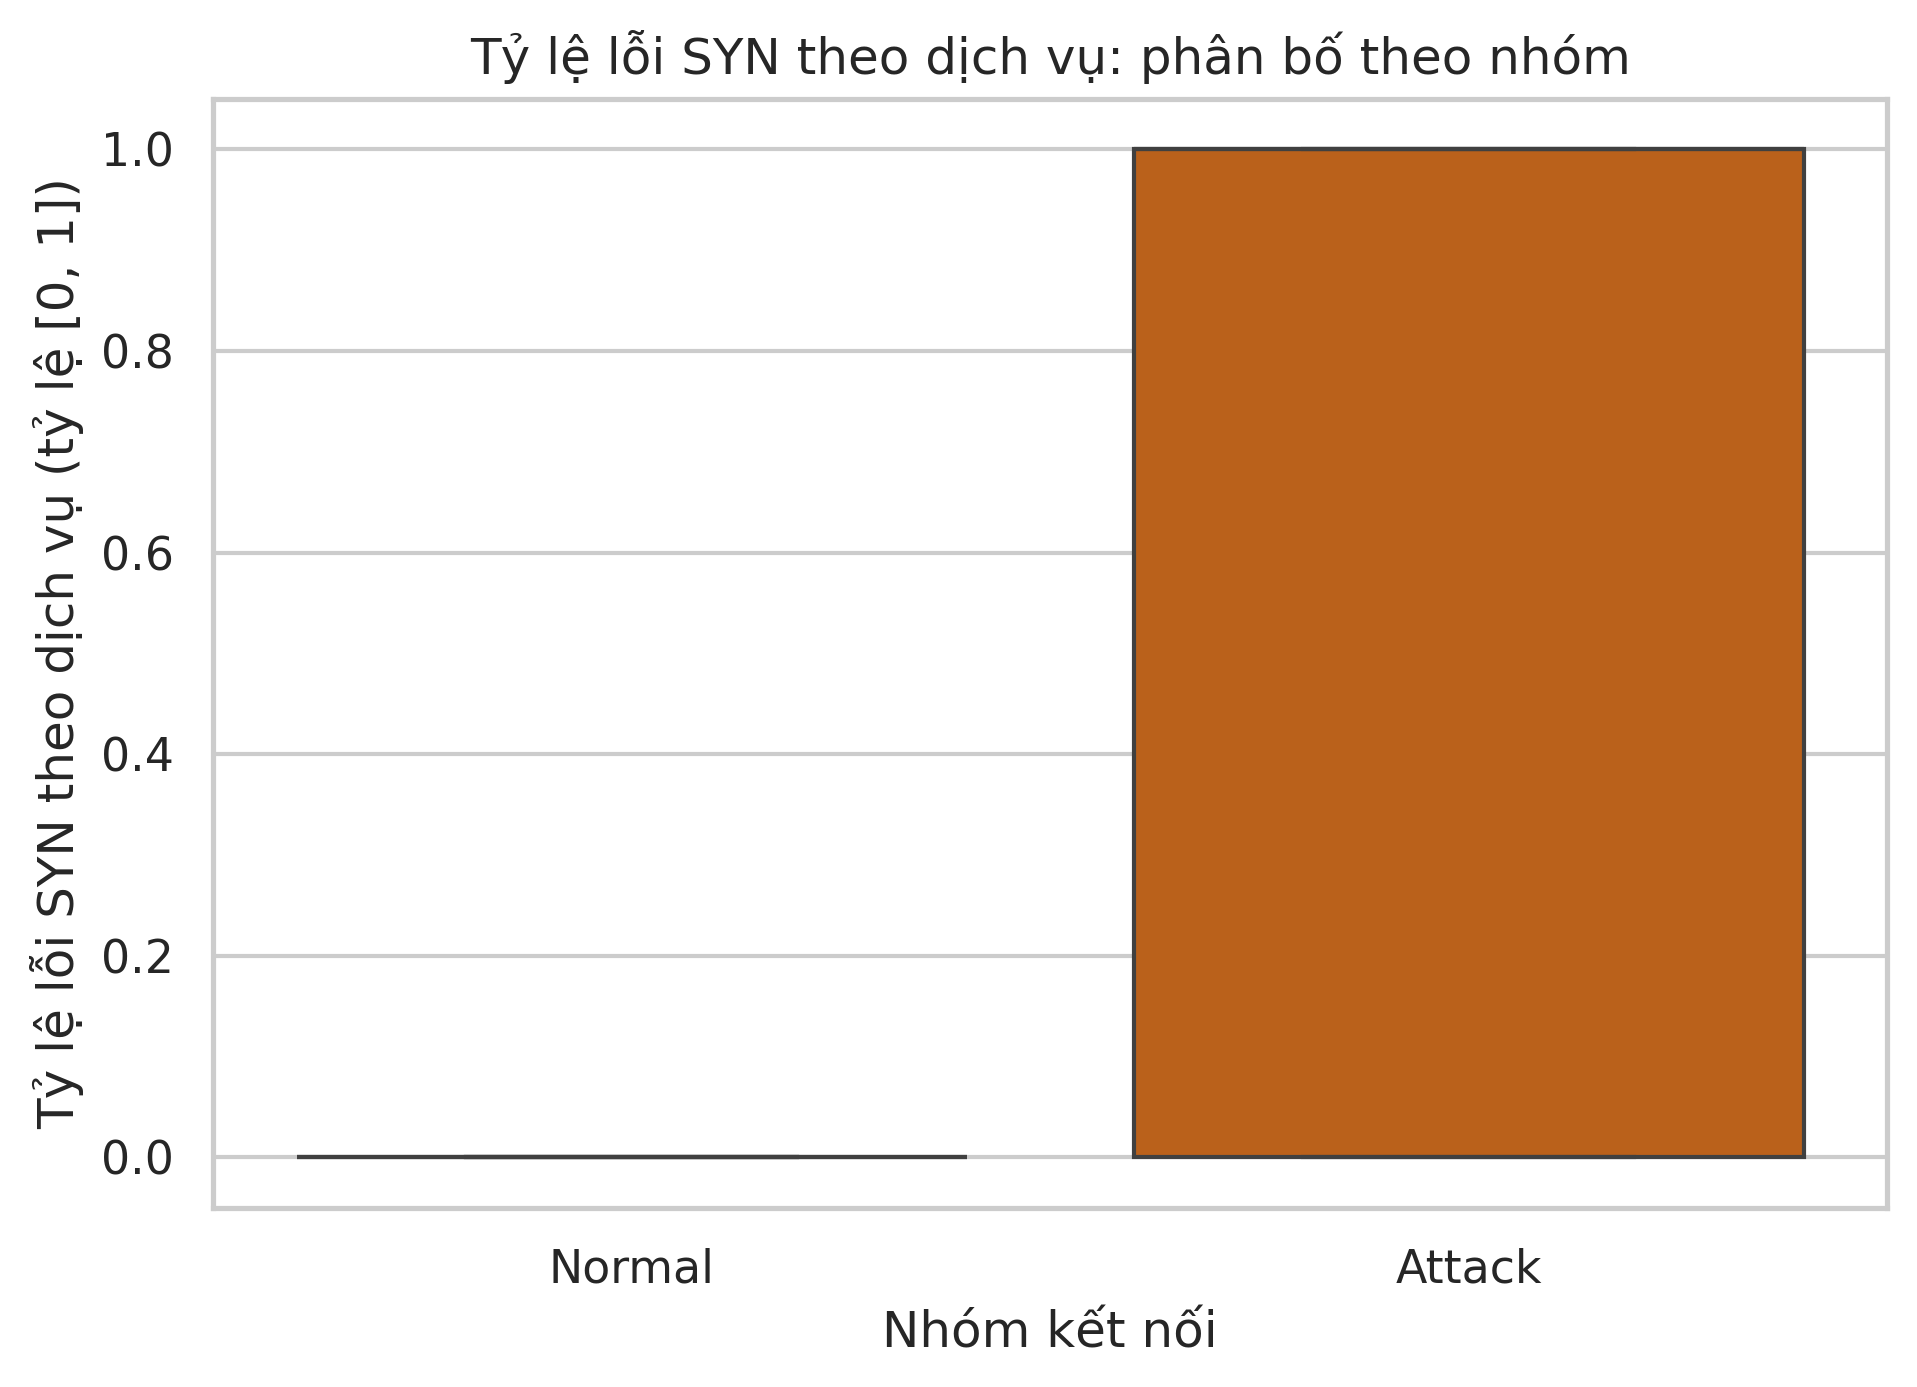

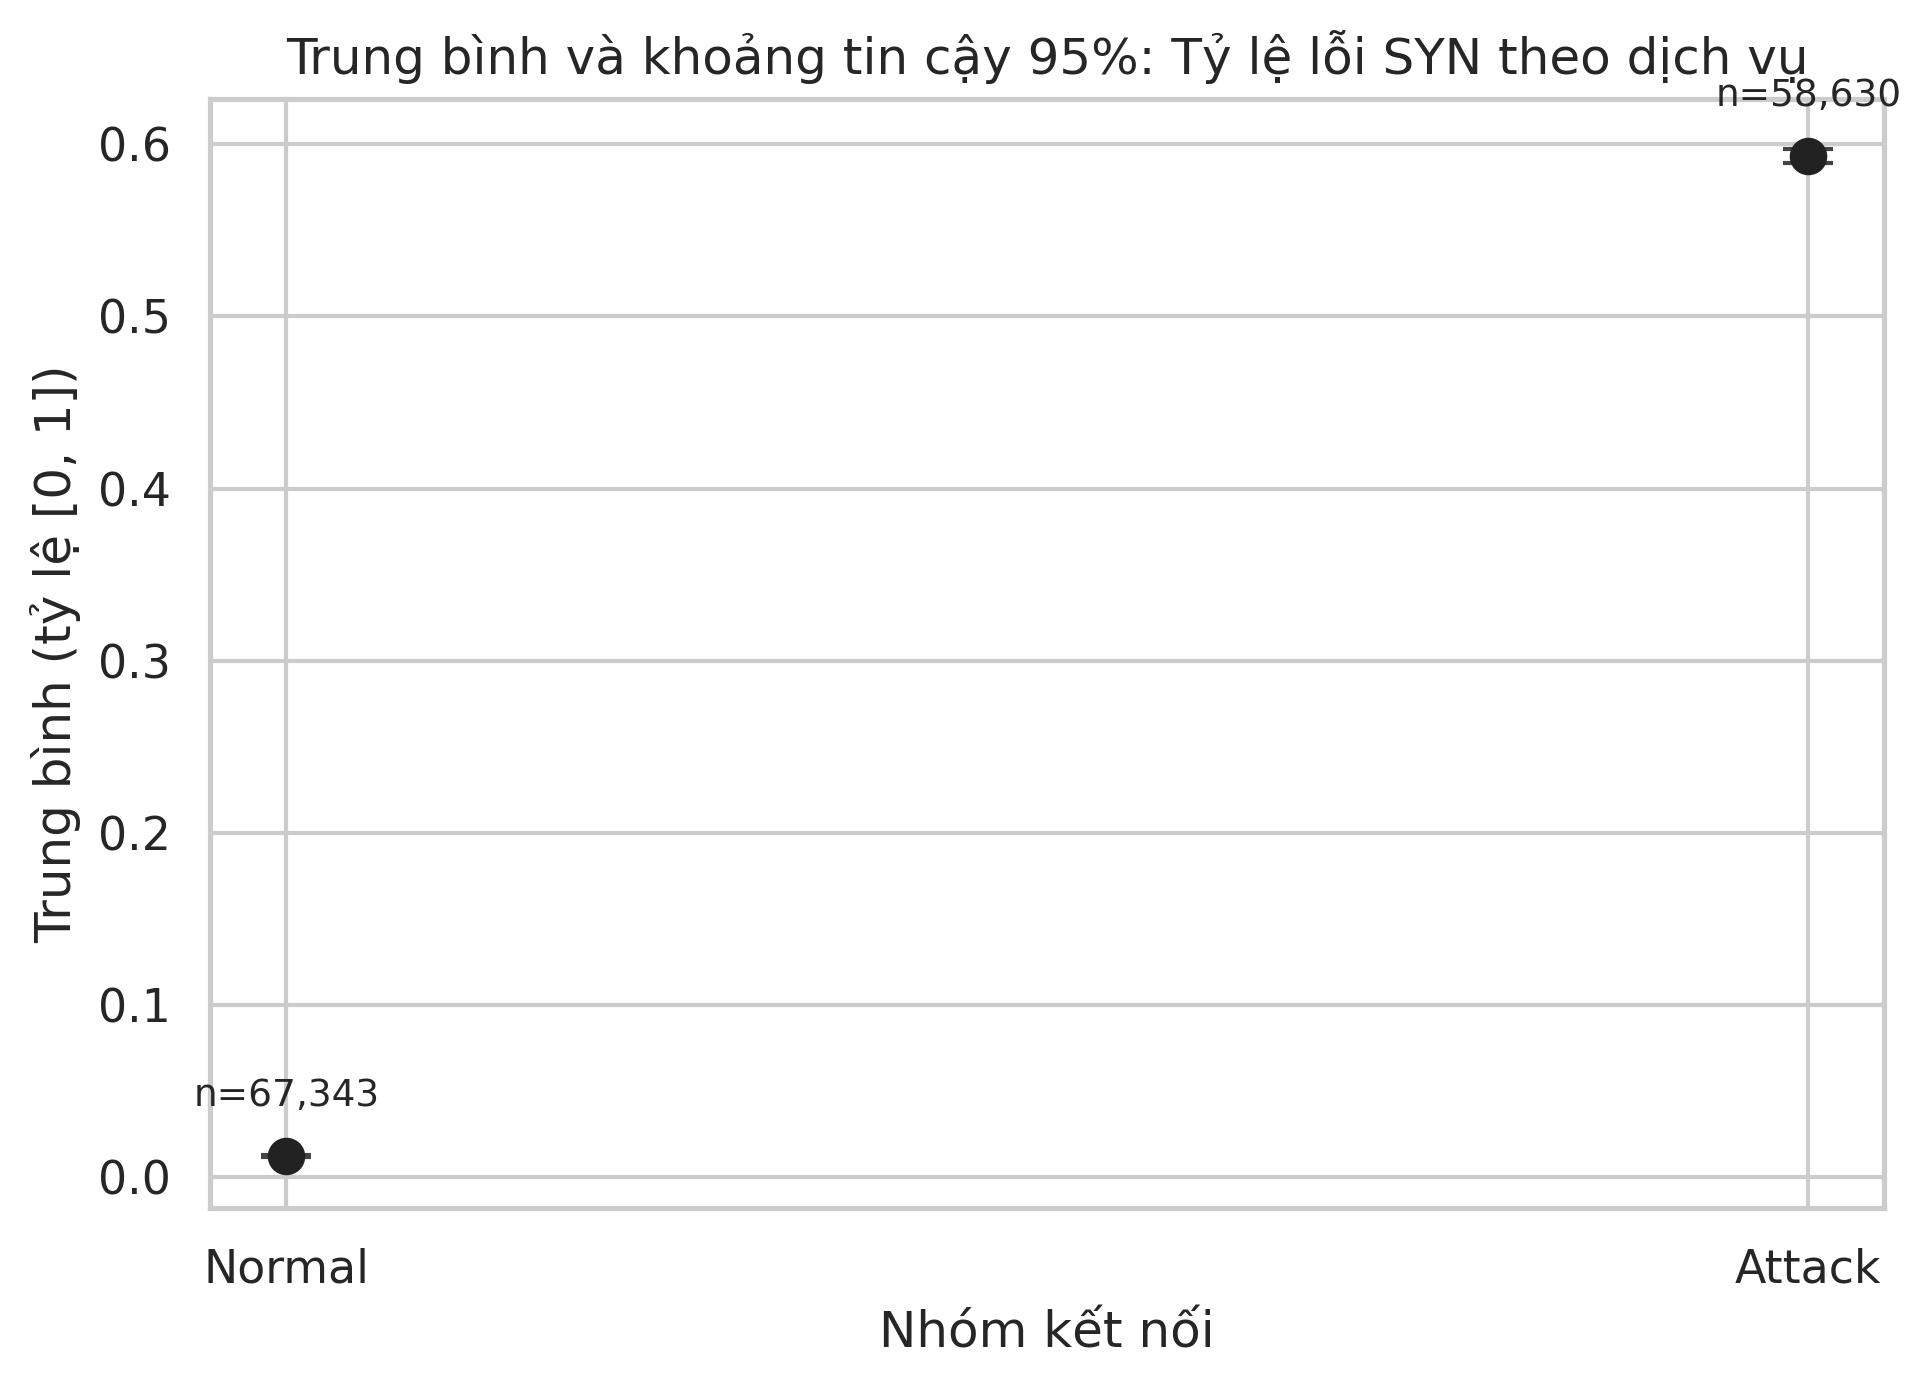

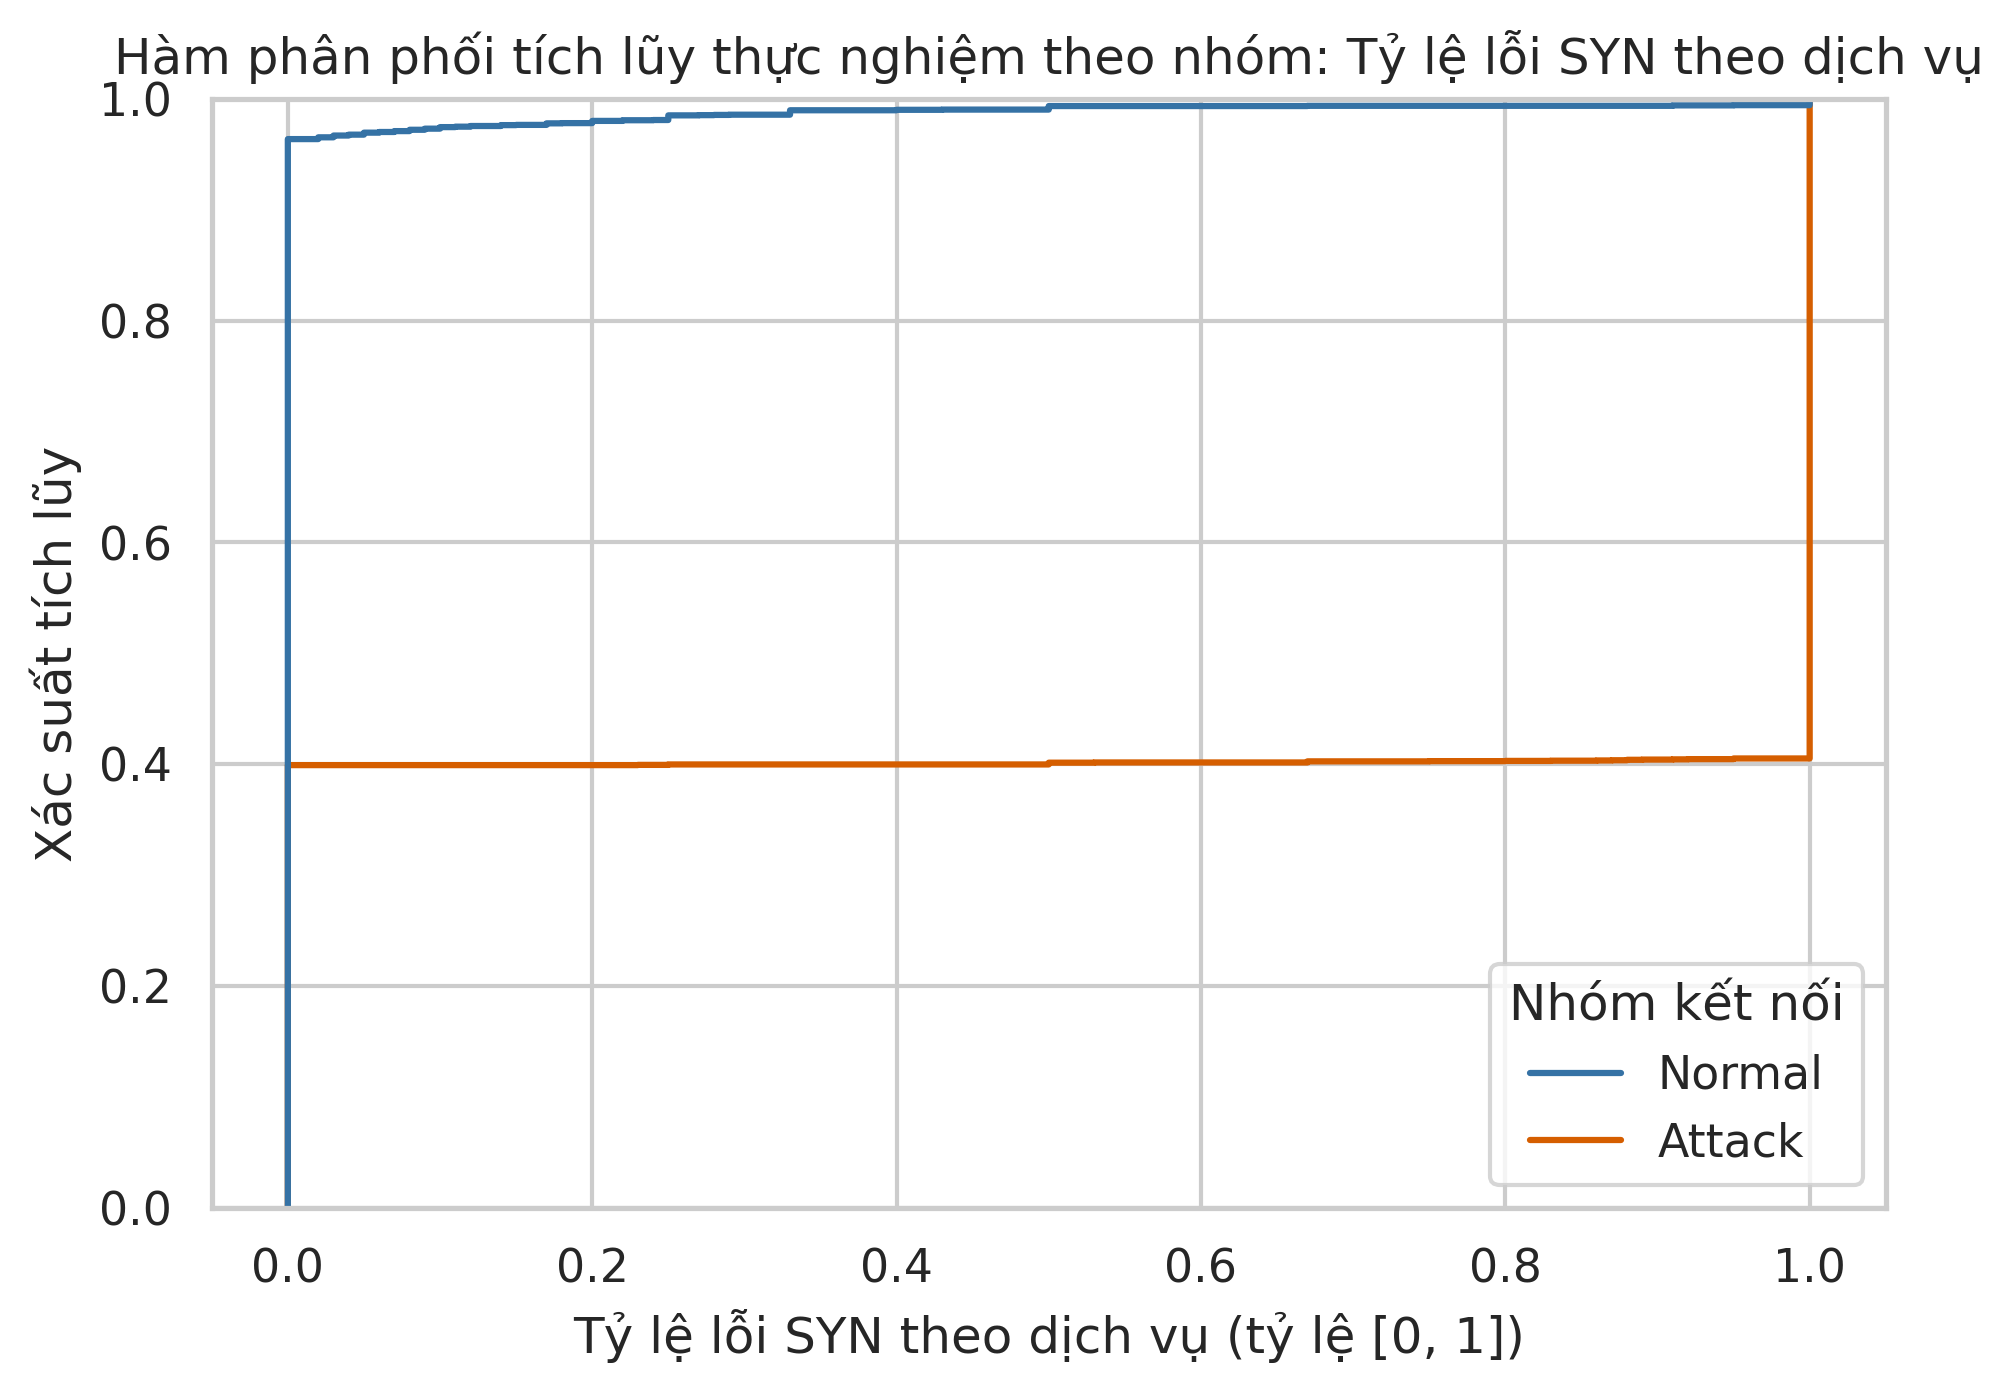

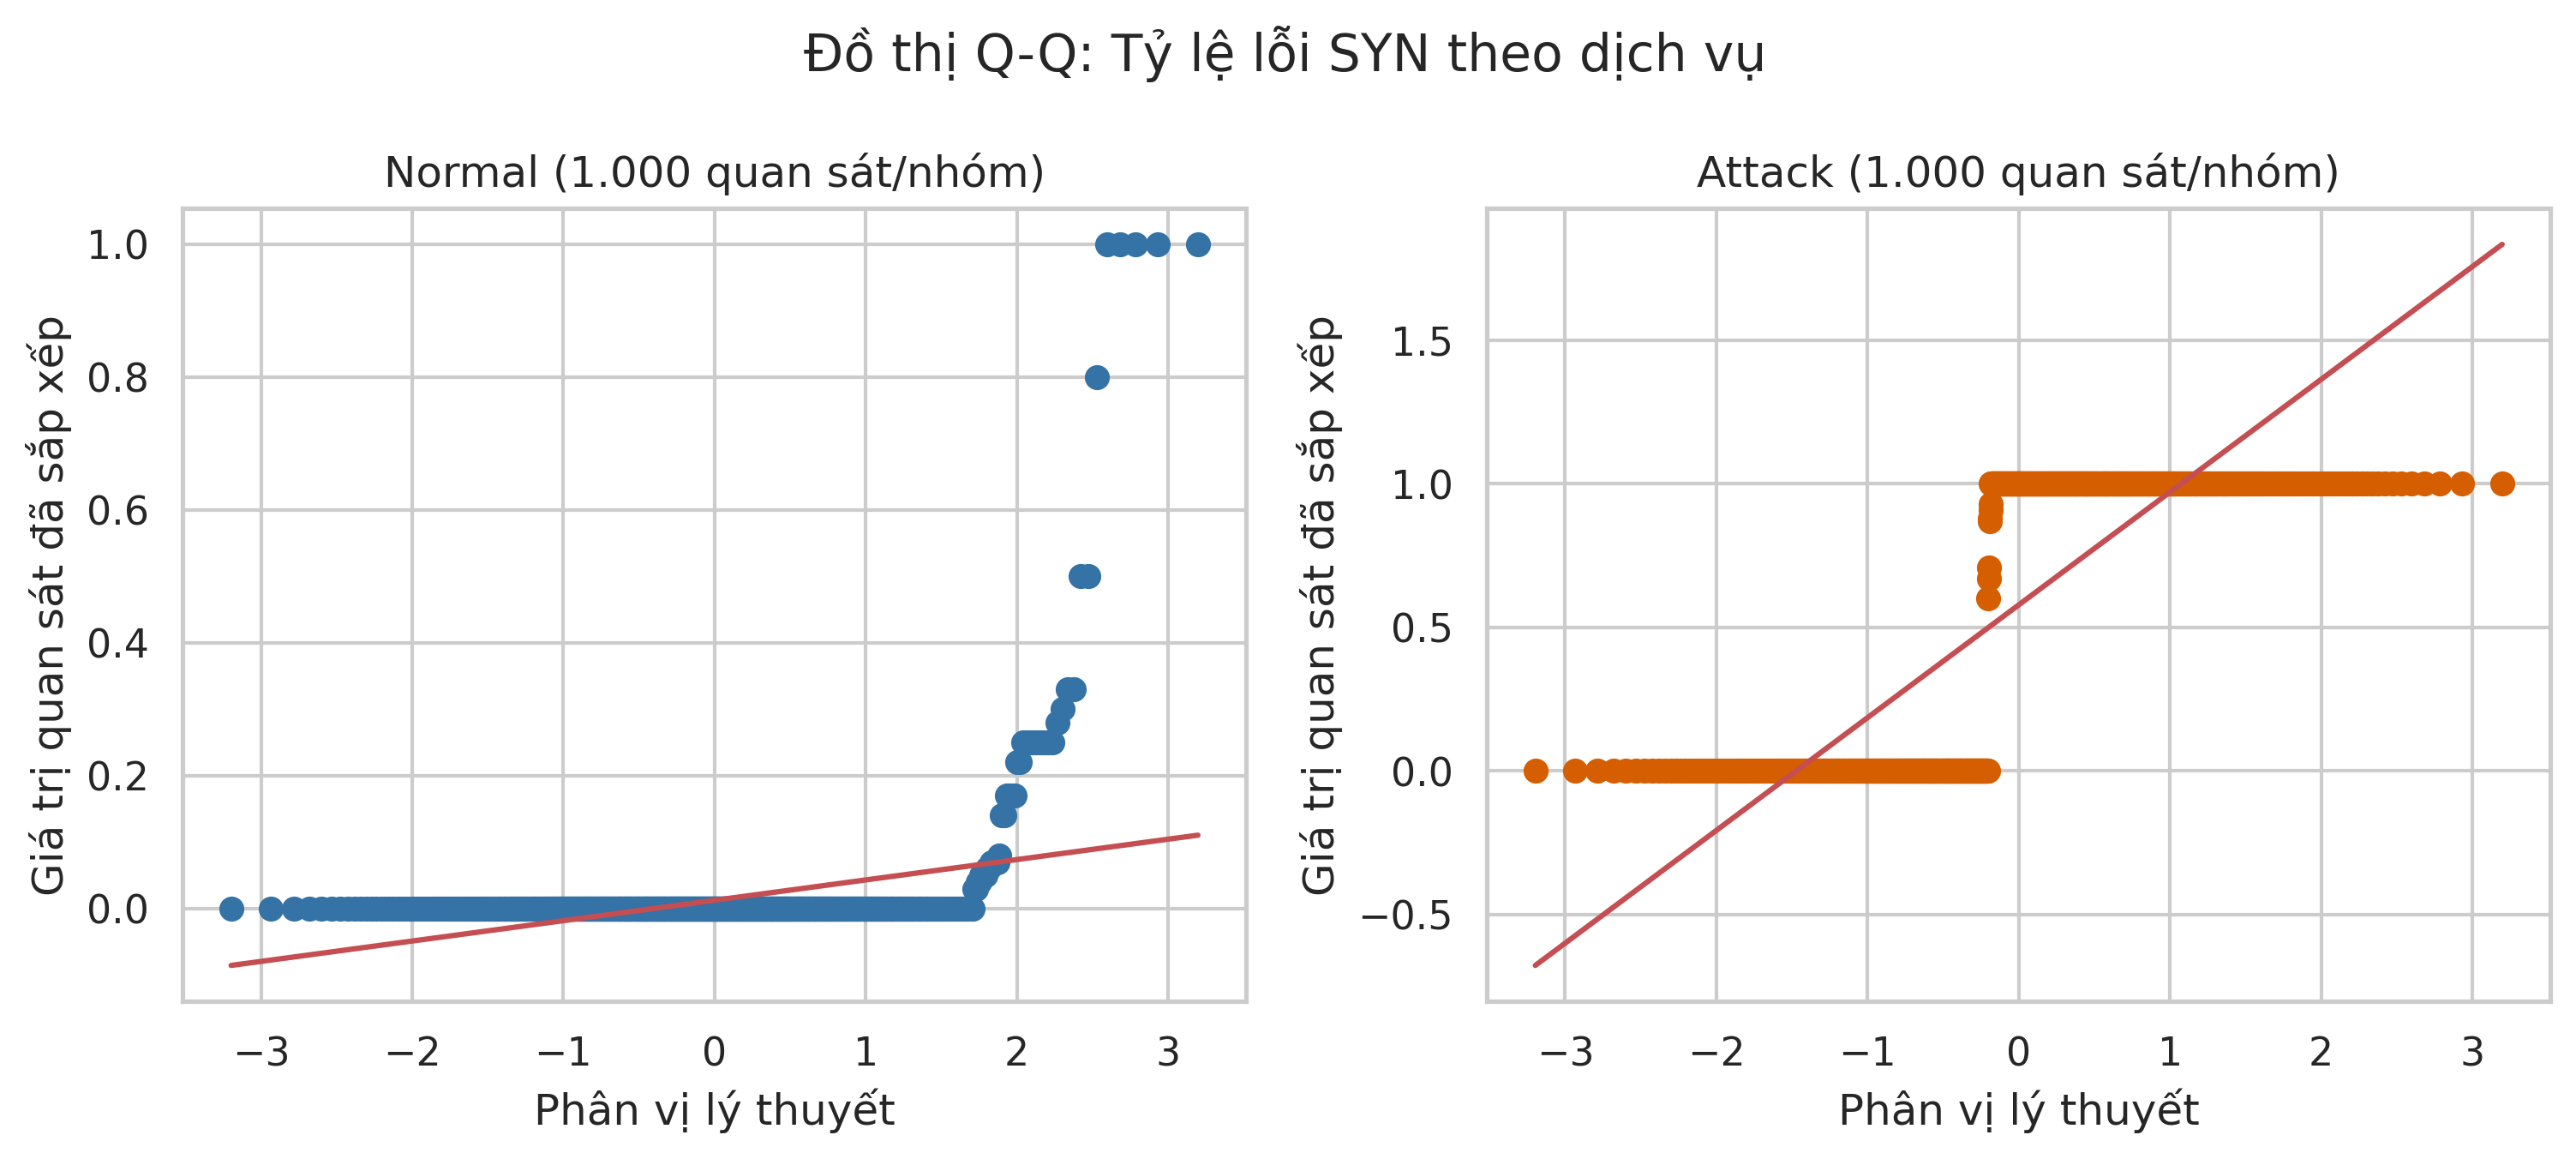

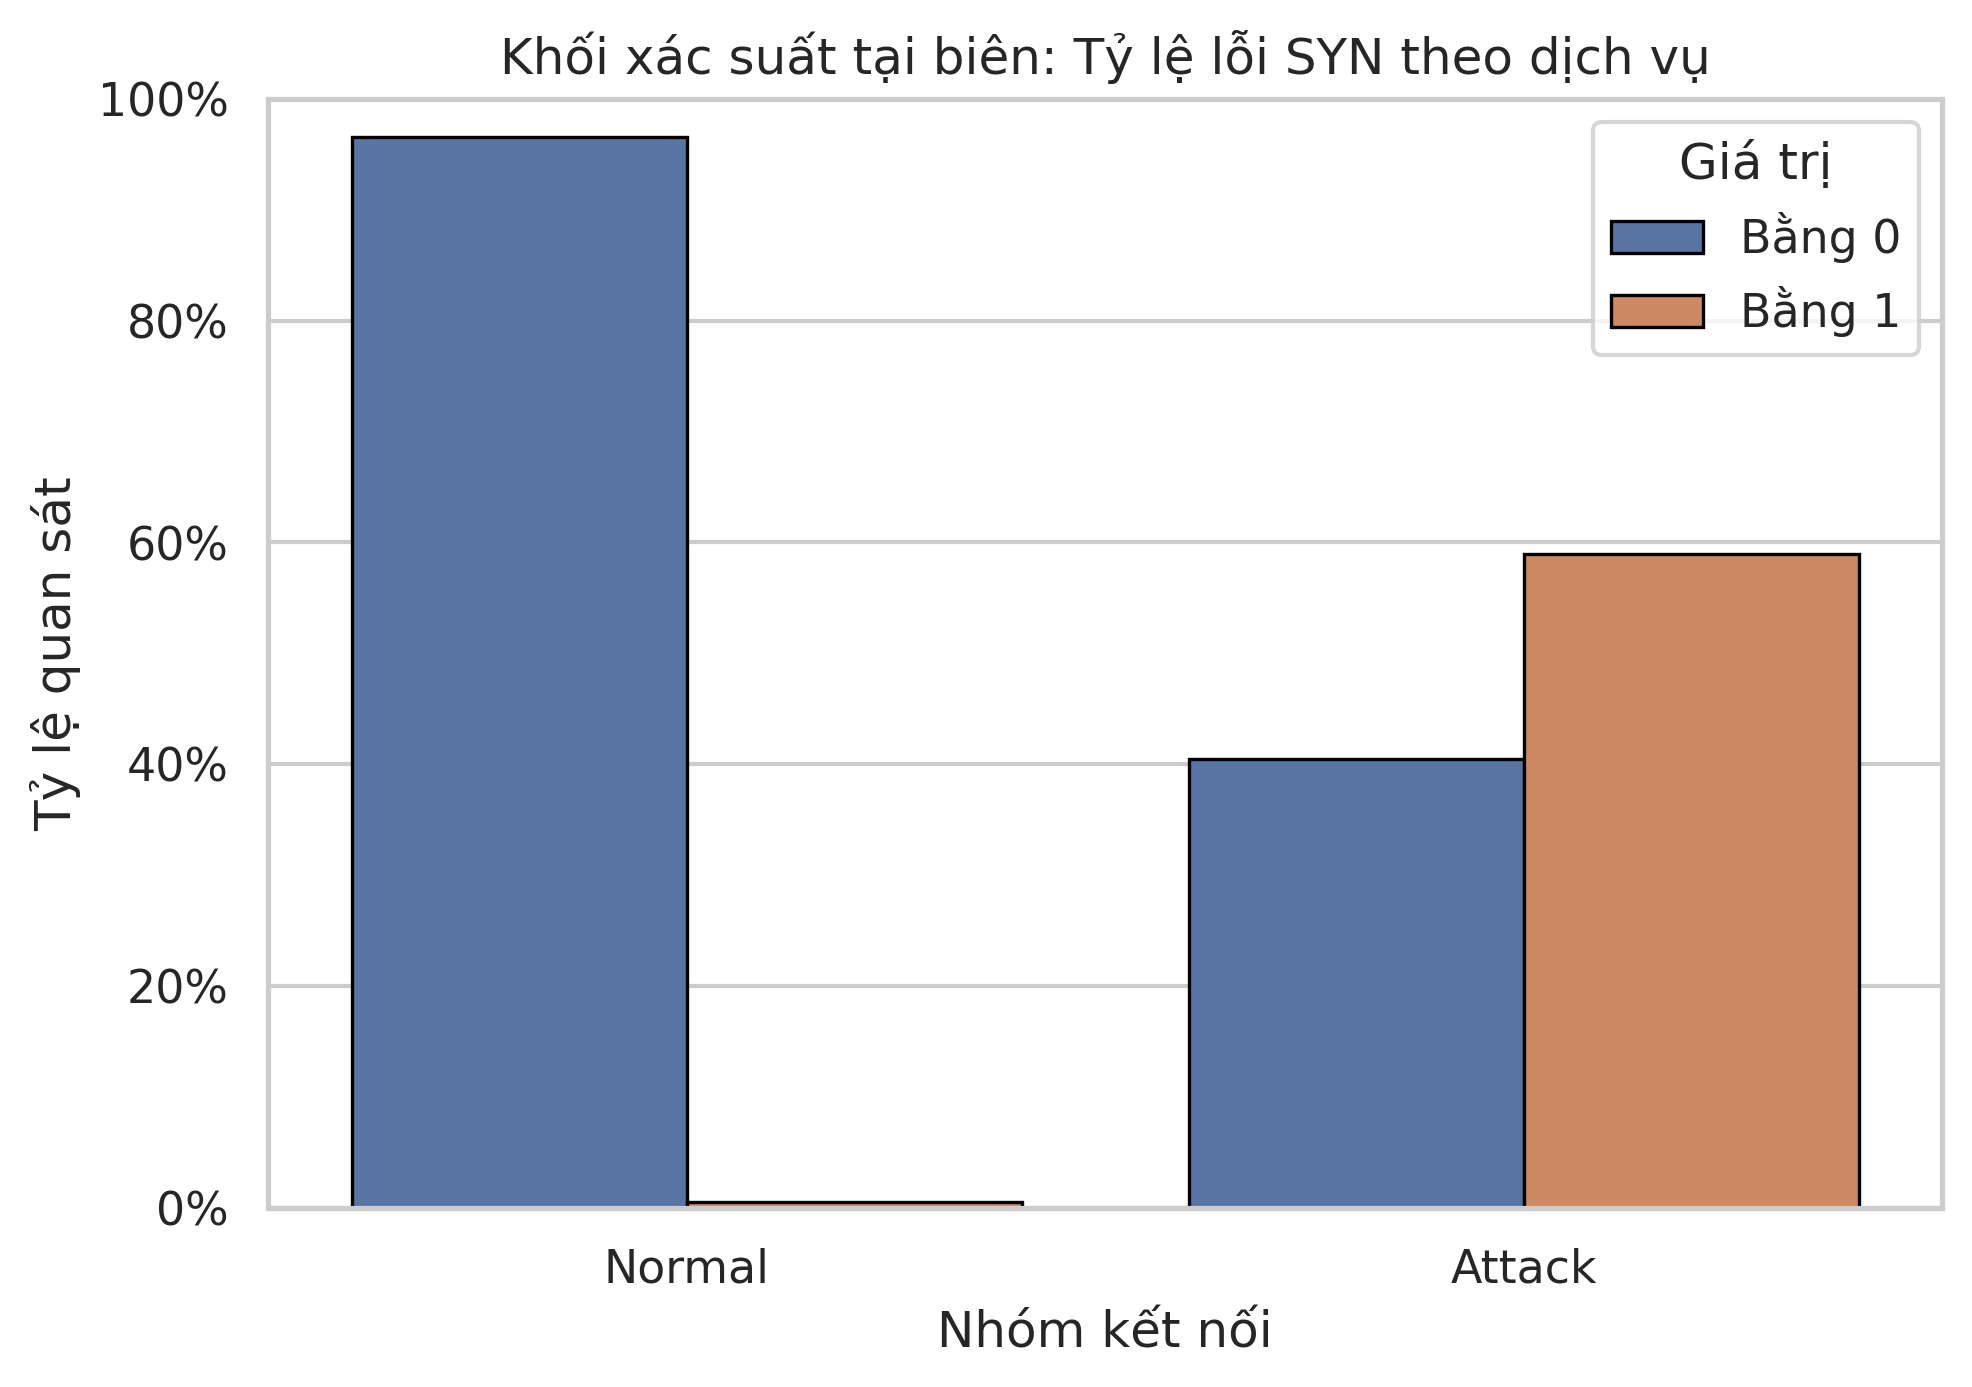

### RQ2 — `srv_rerror_rate`

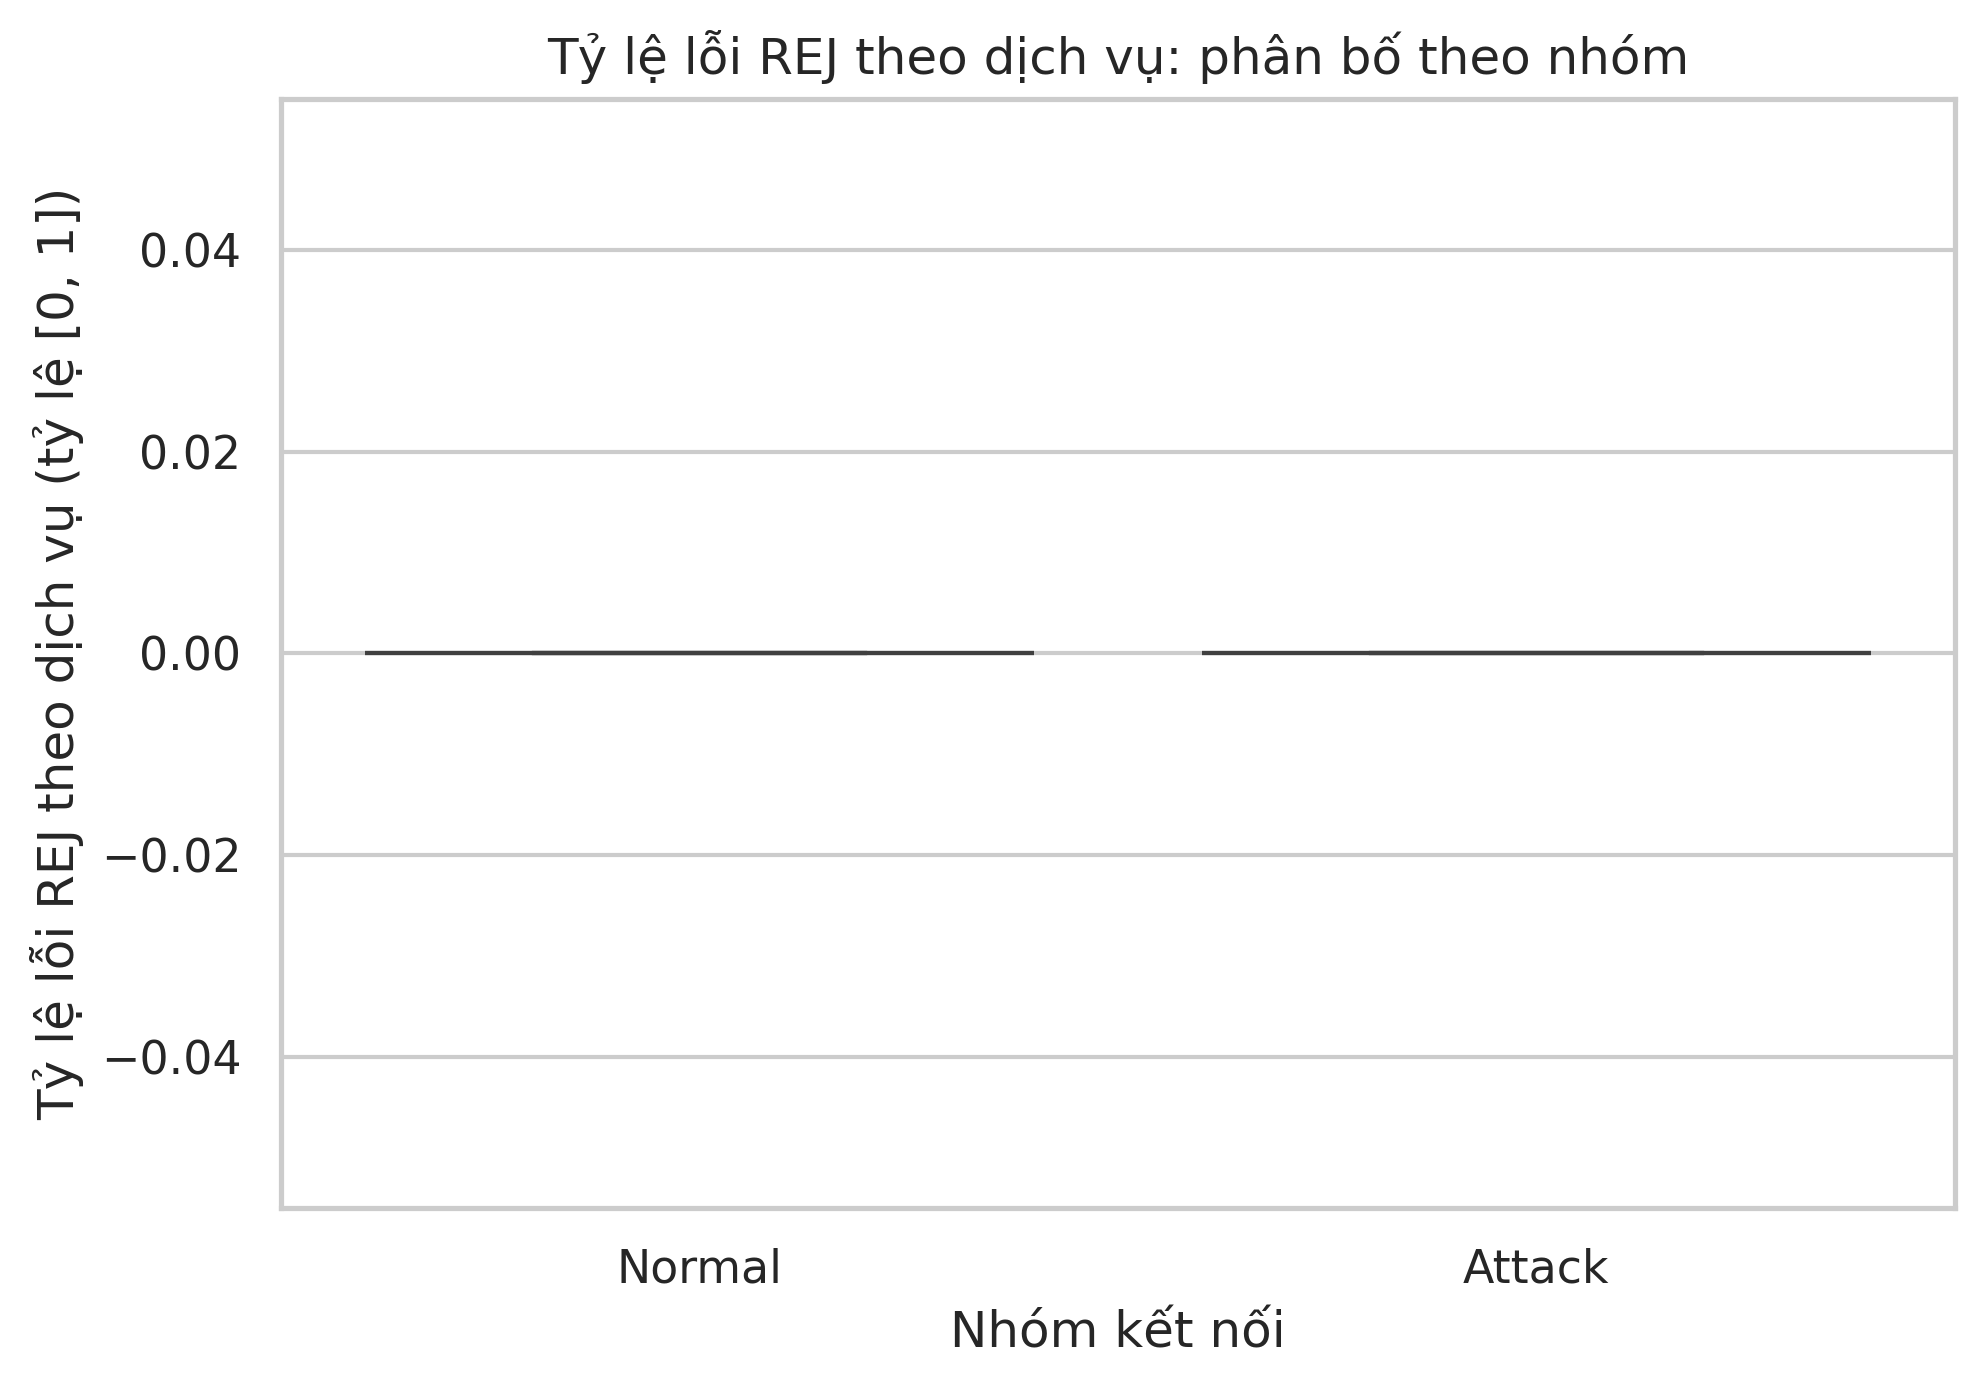

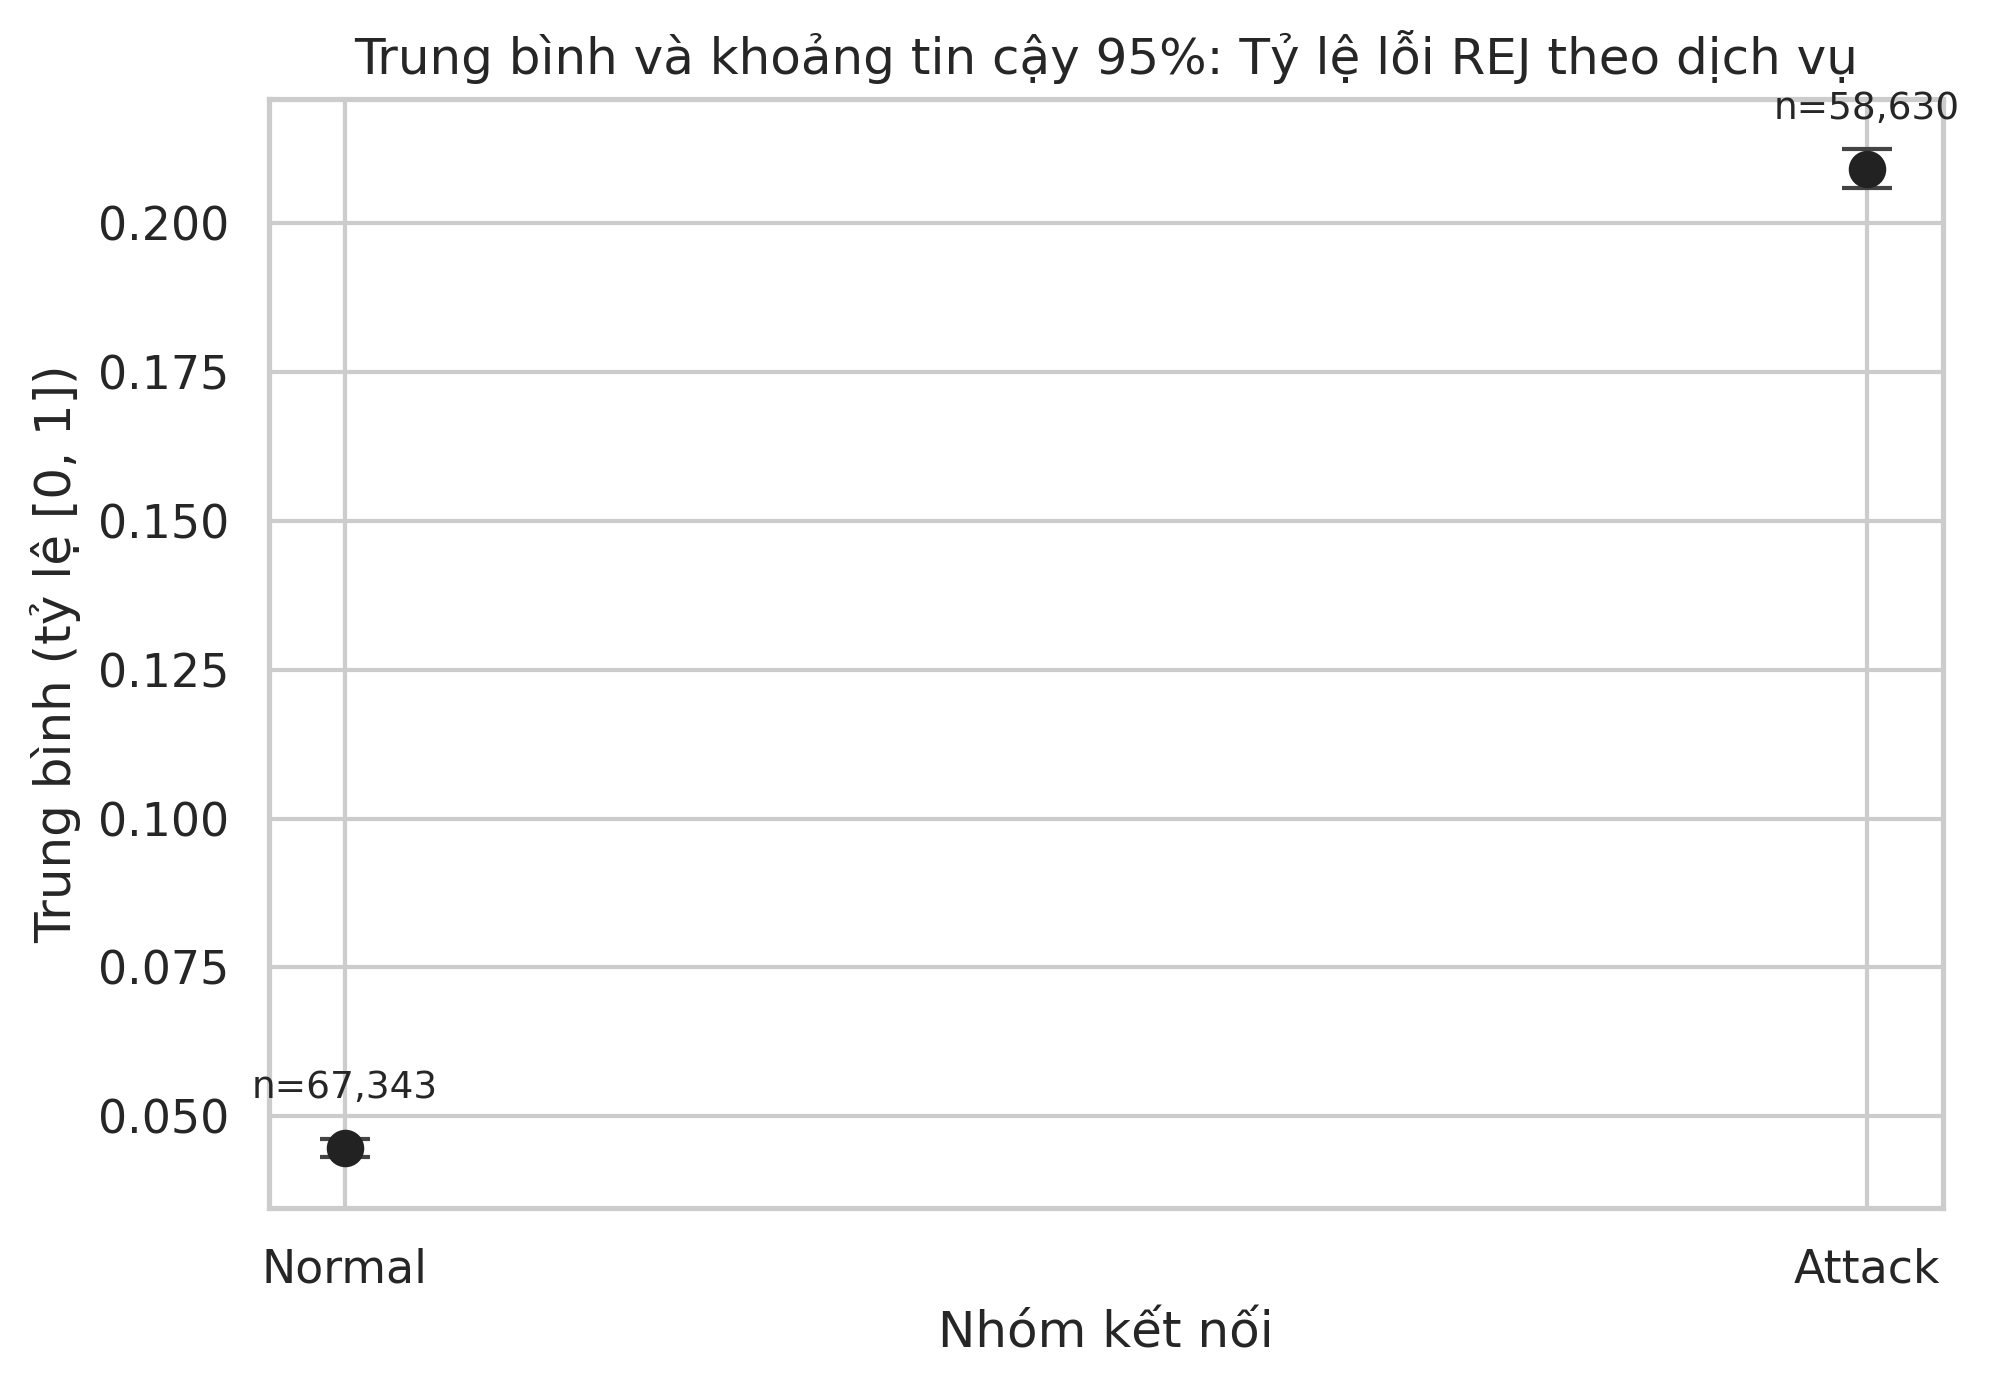

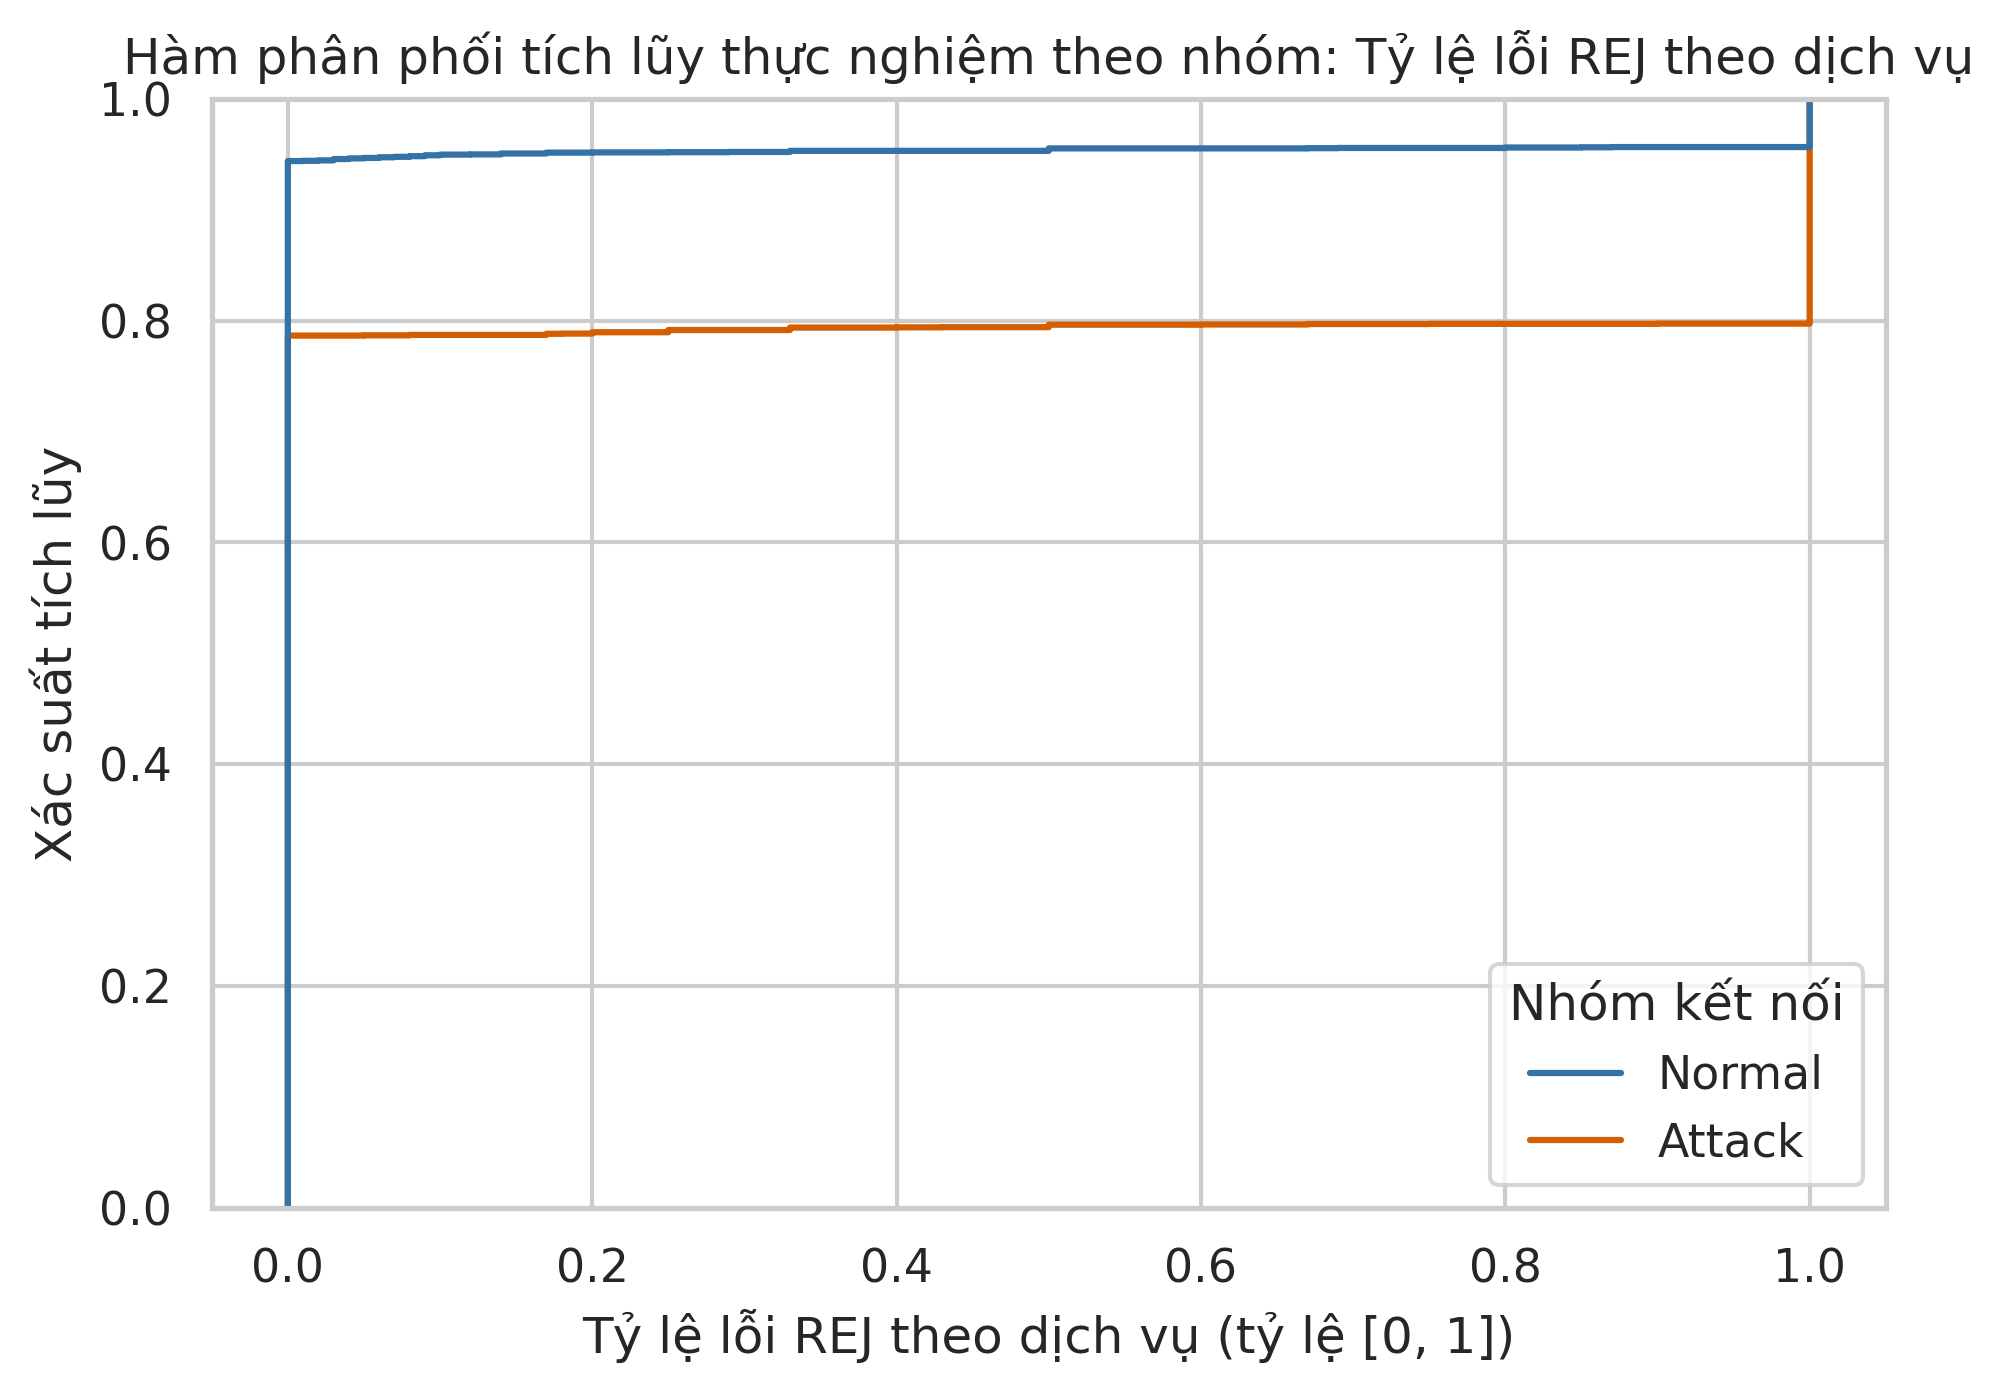

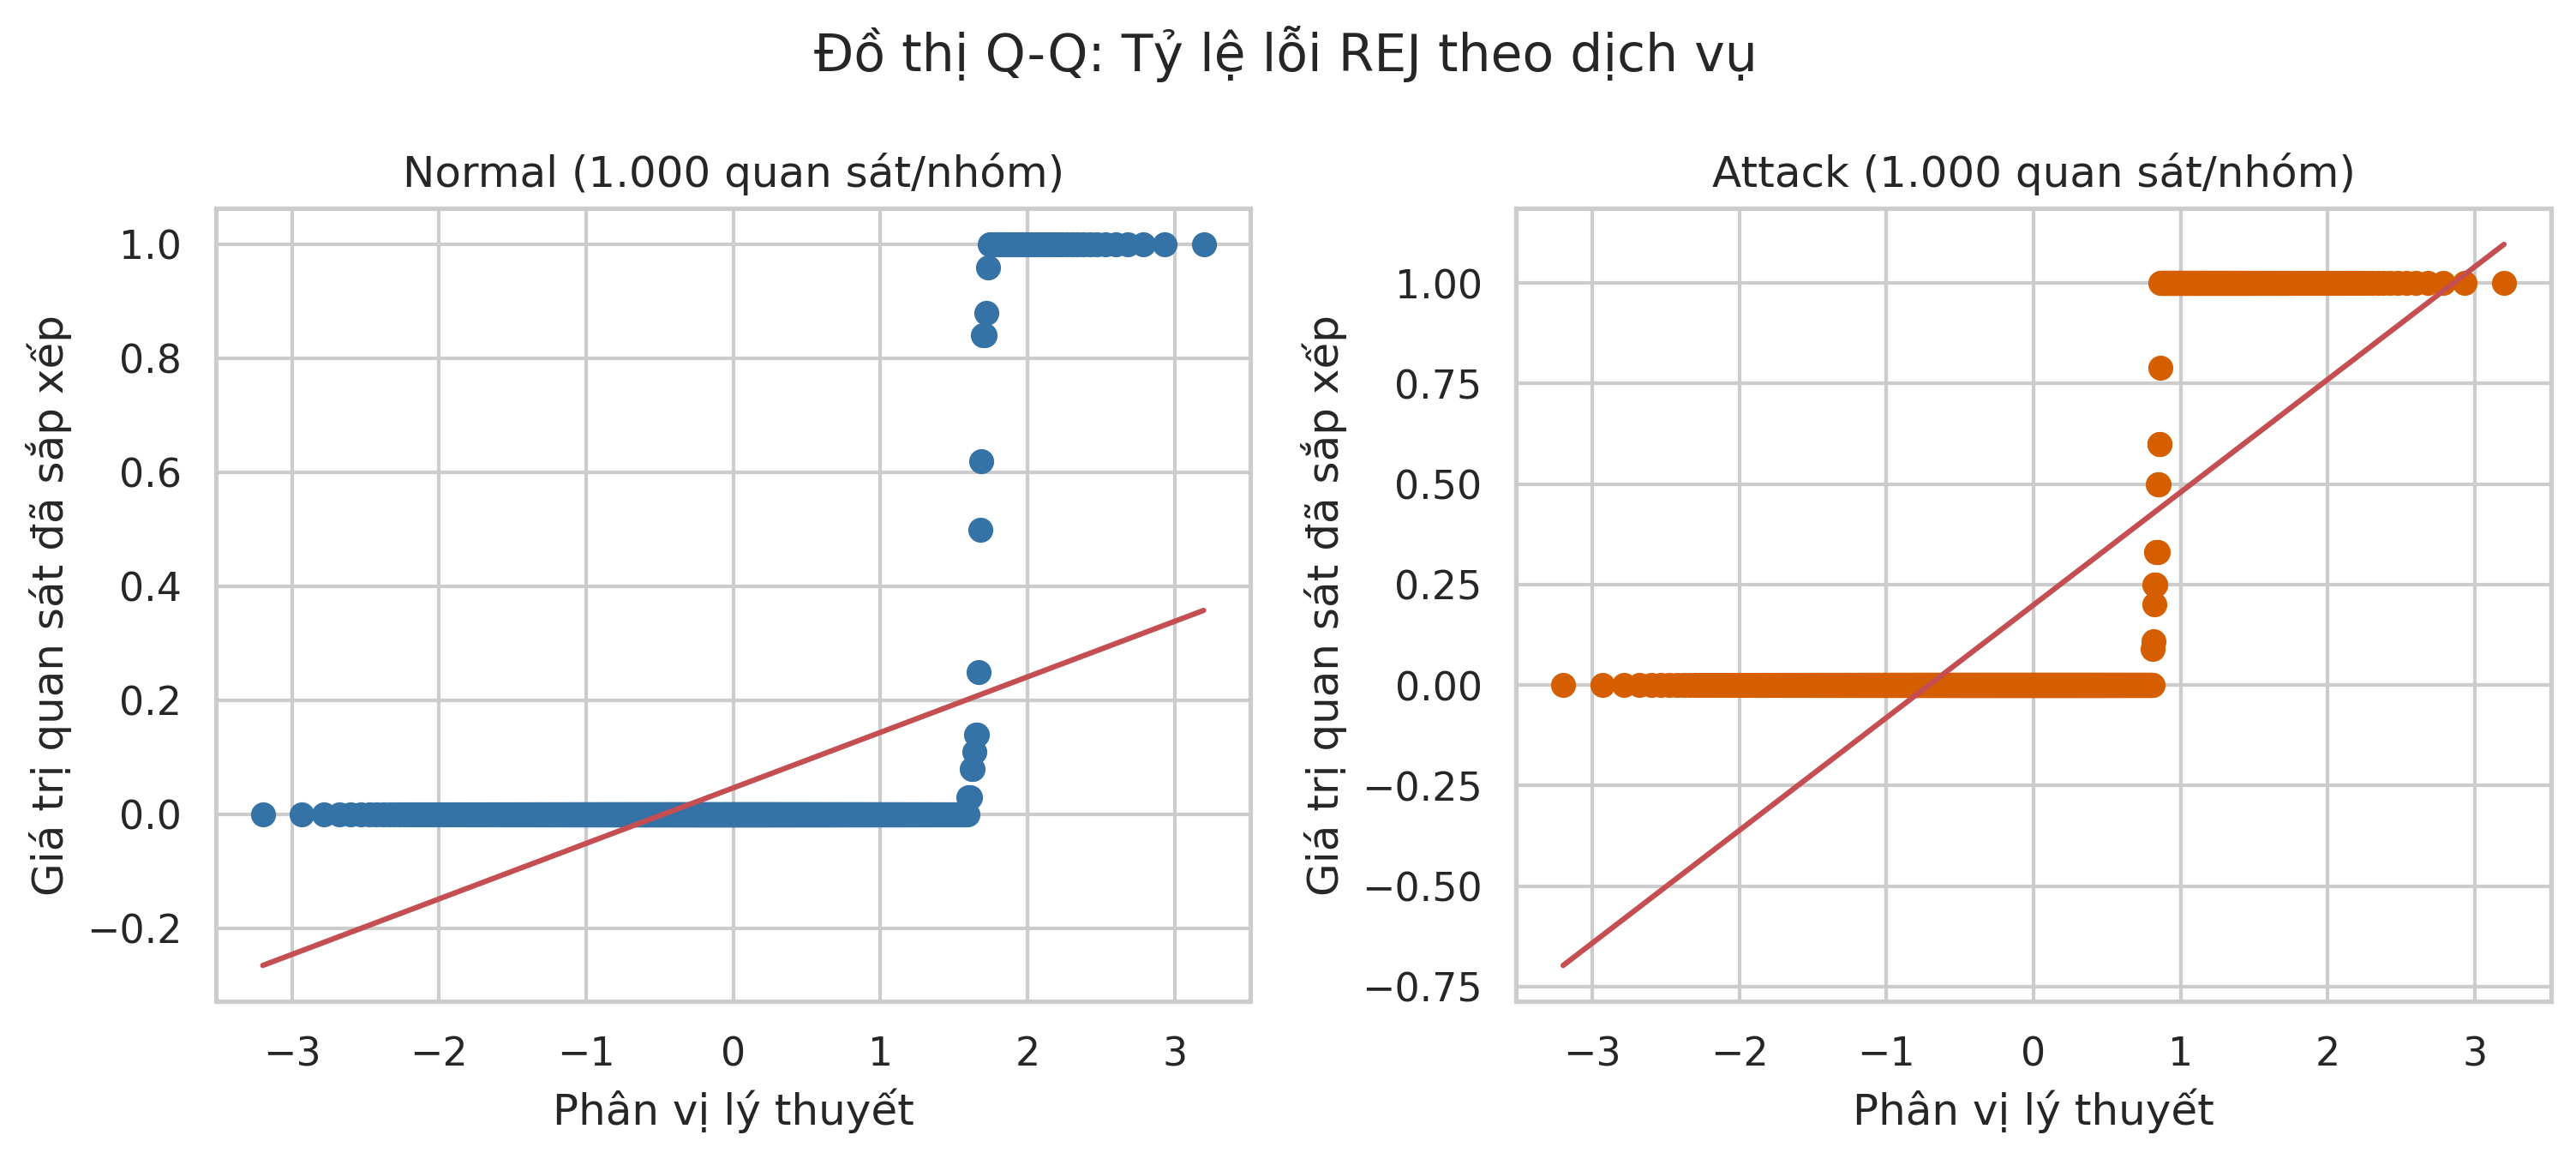

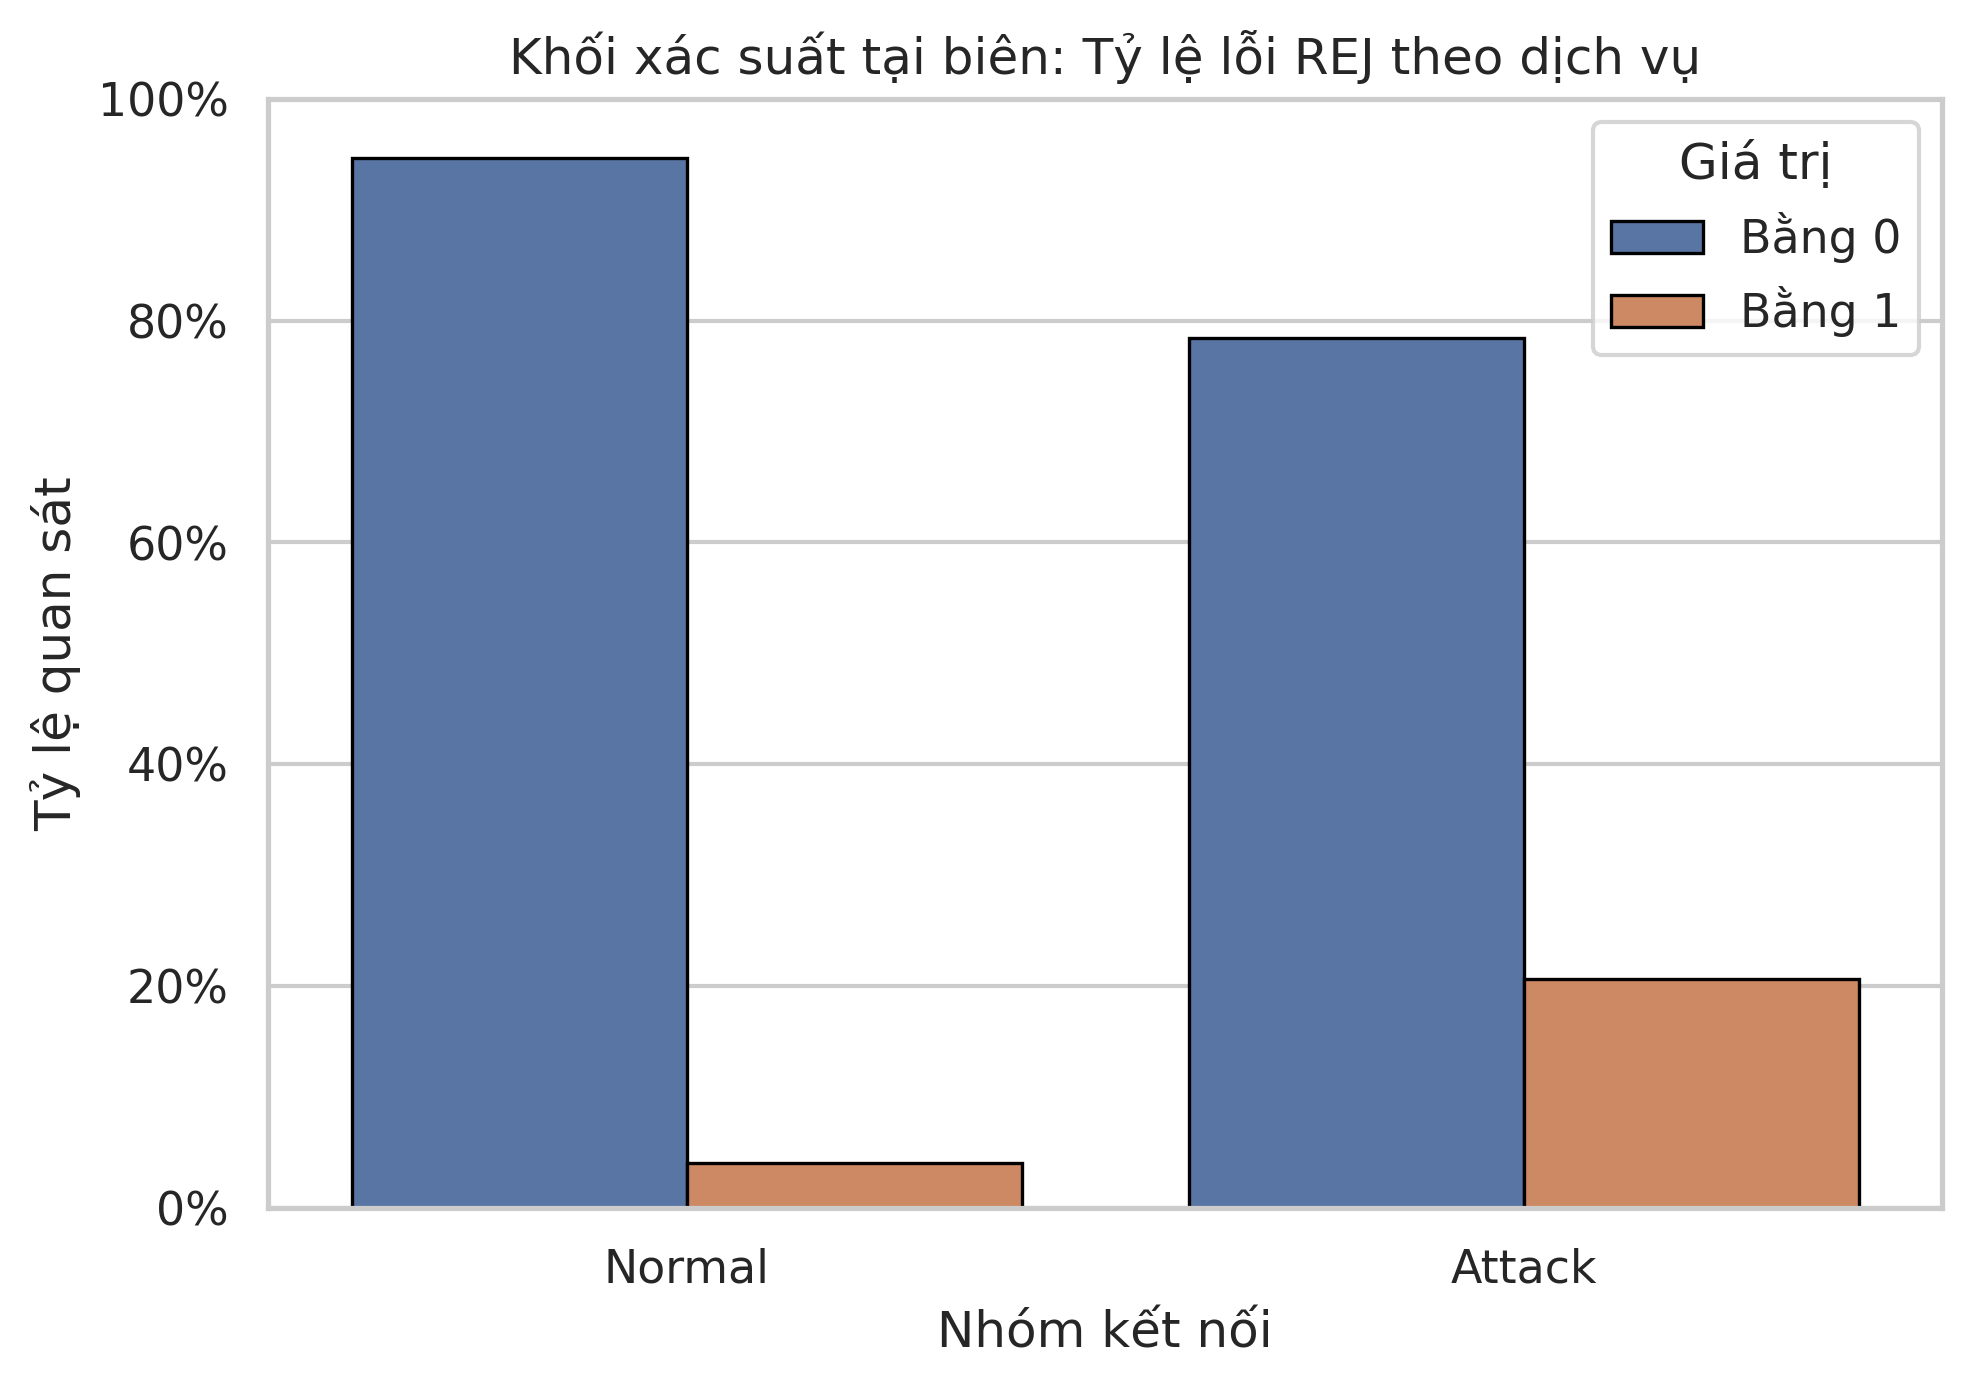

### RQ3 — `count`

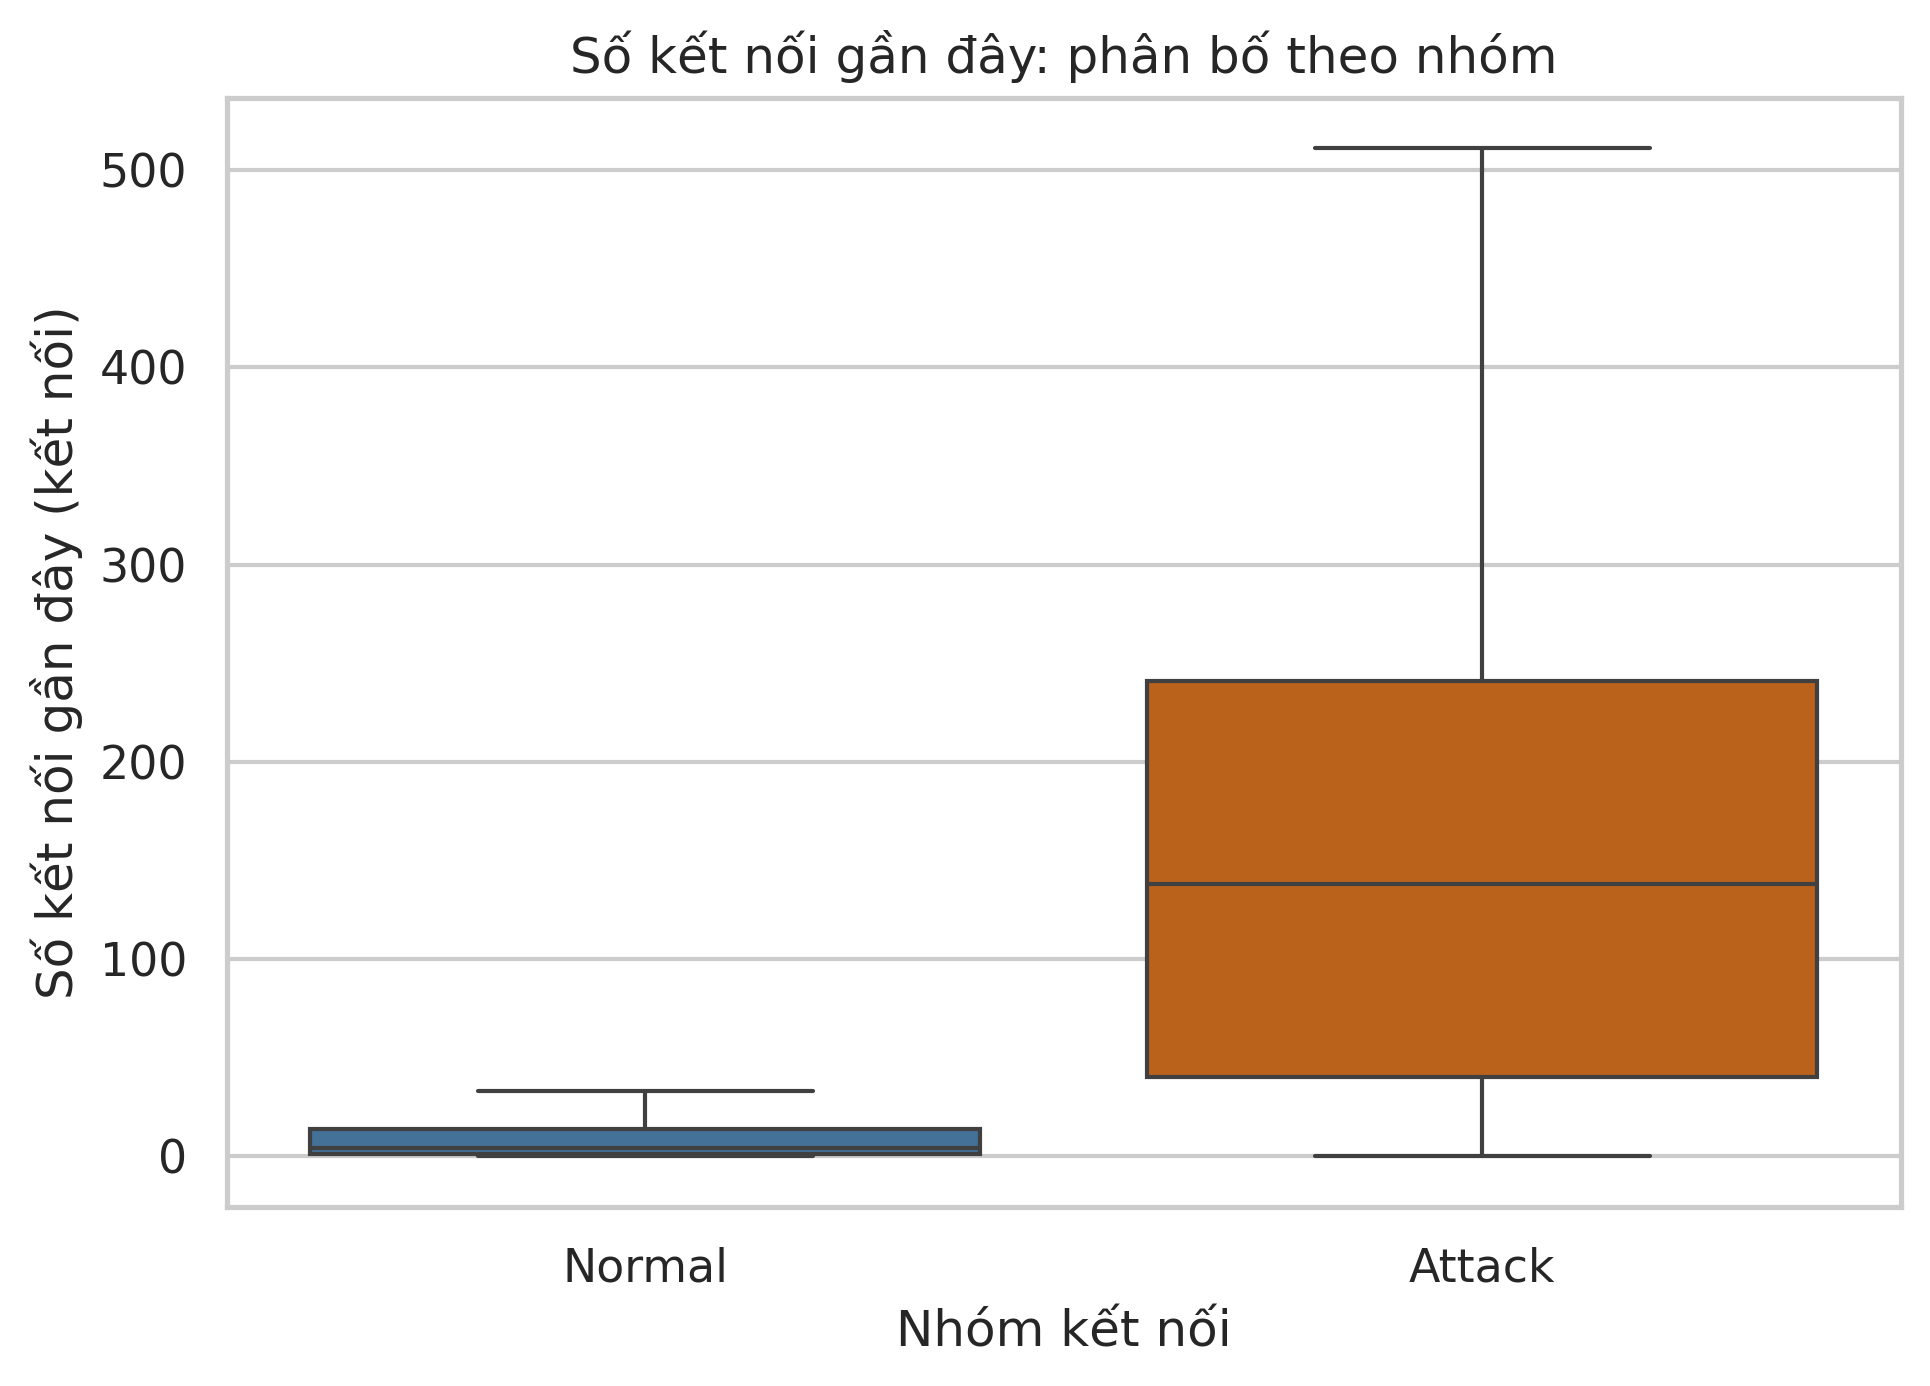

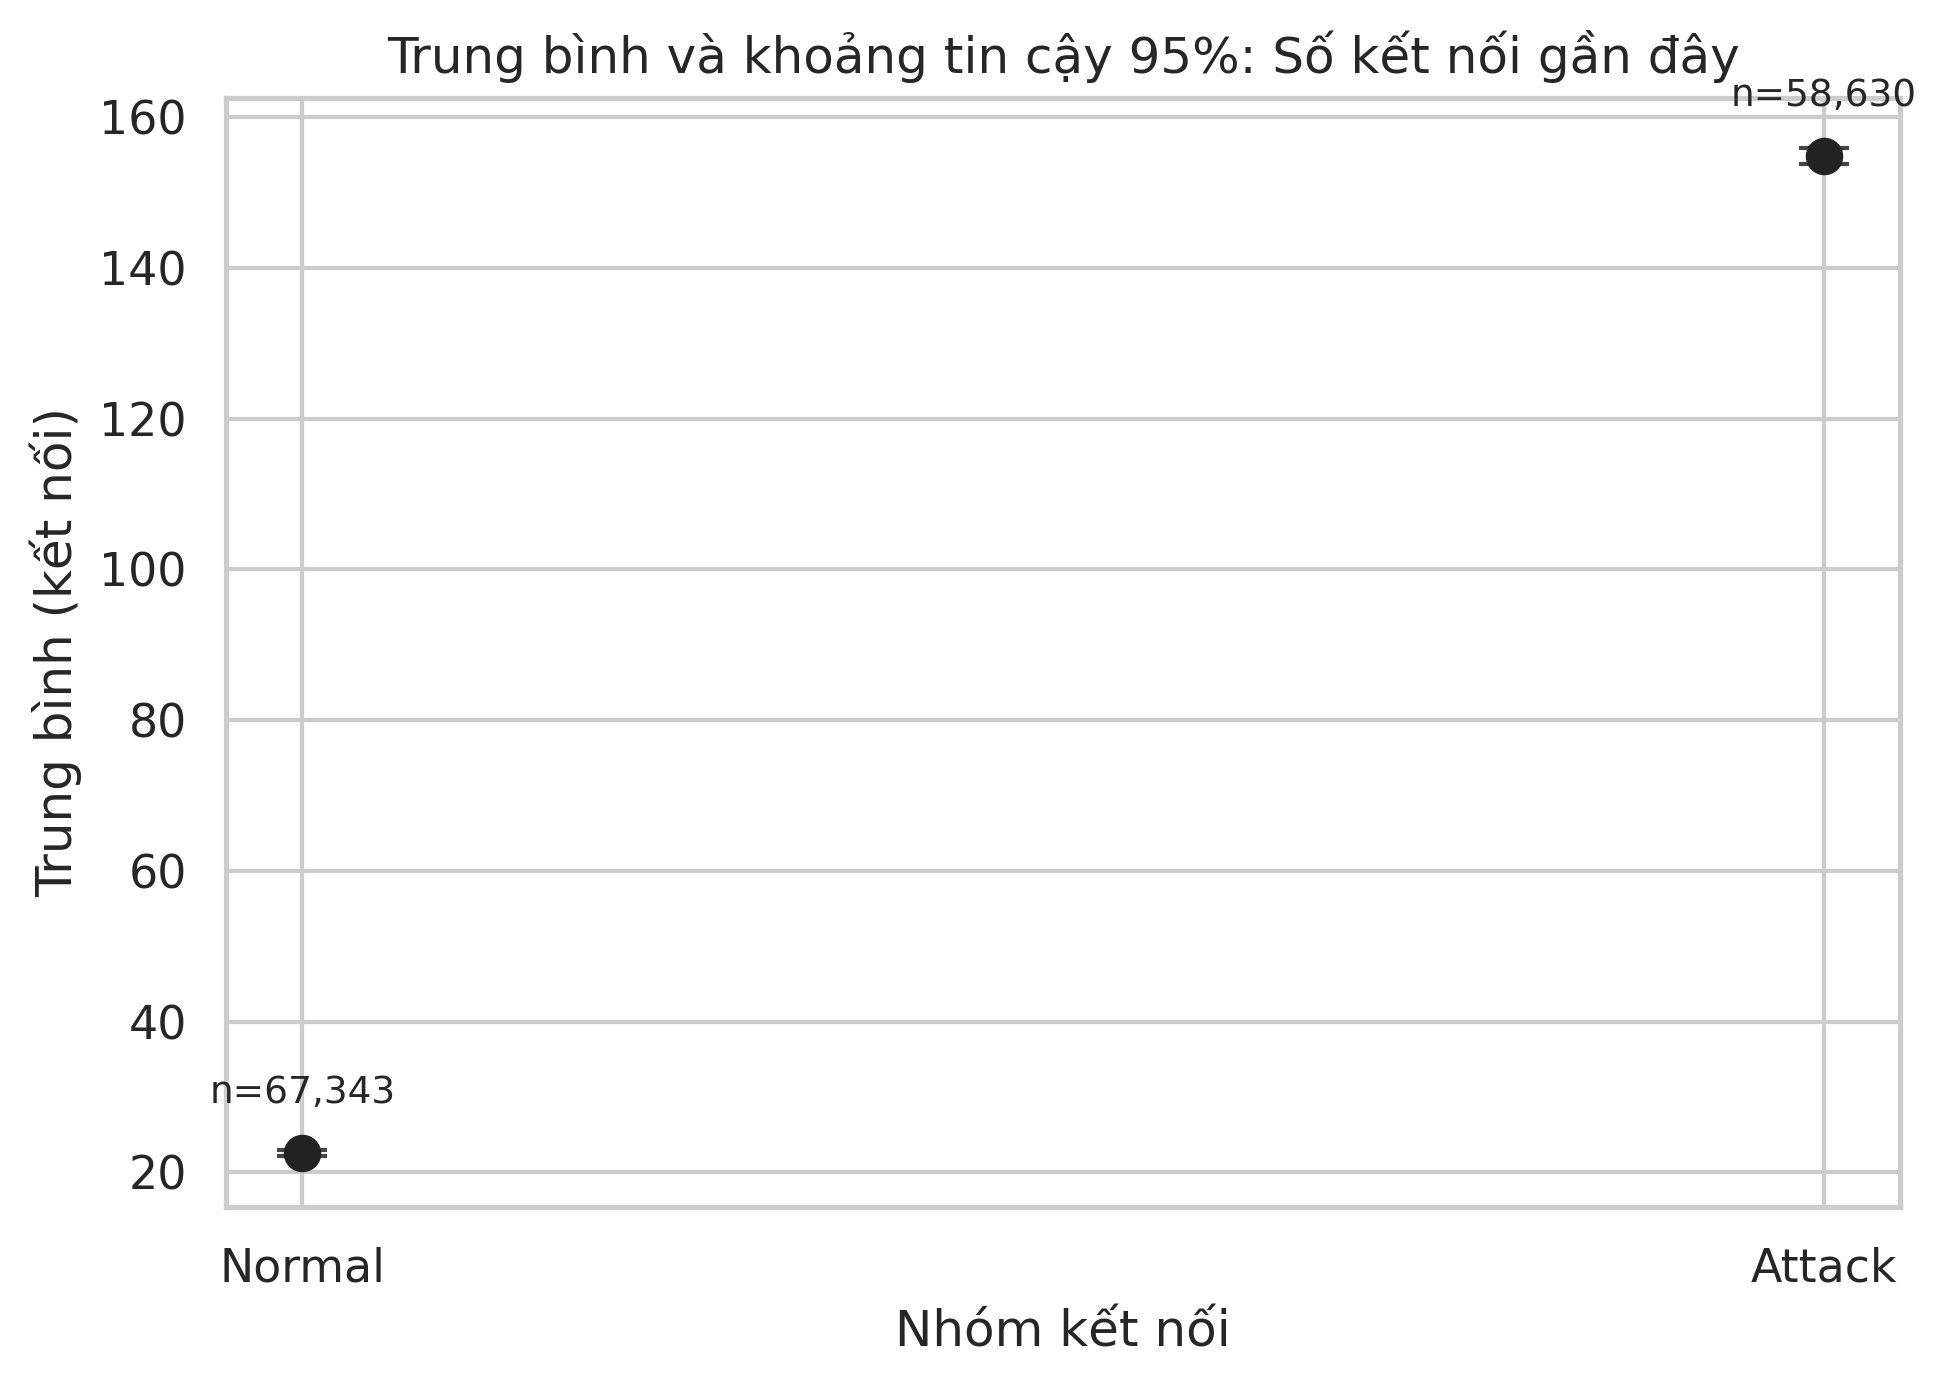

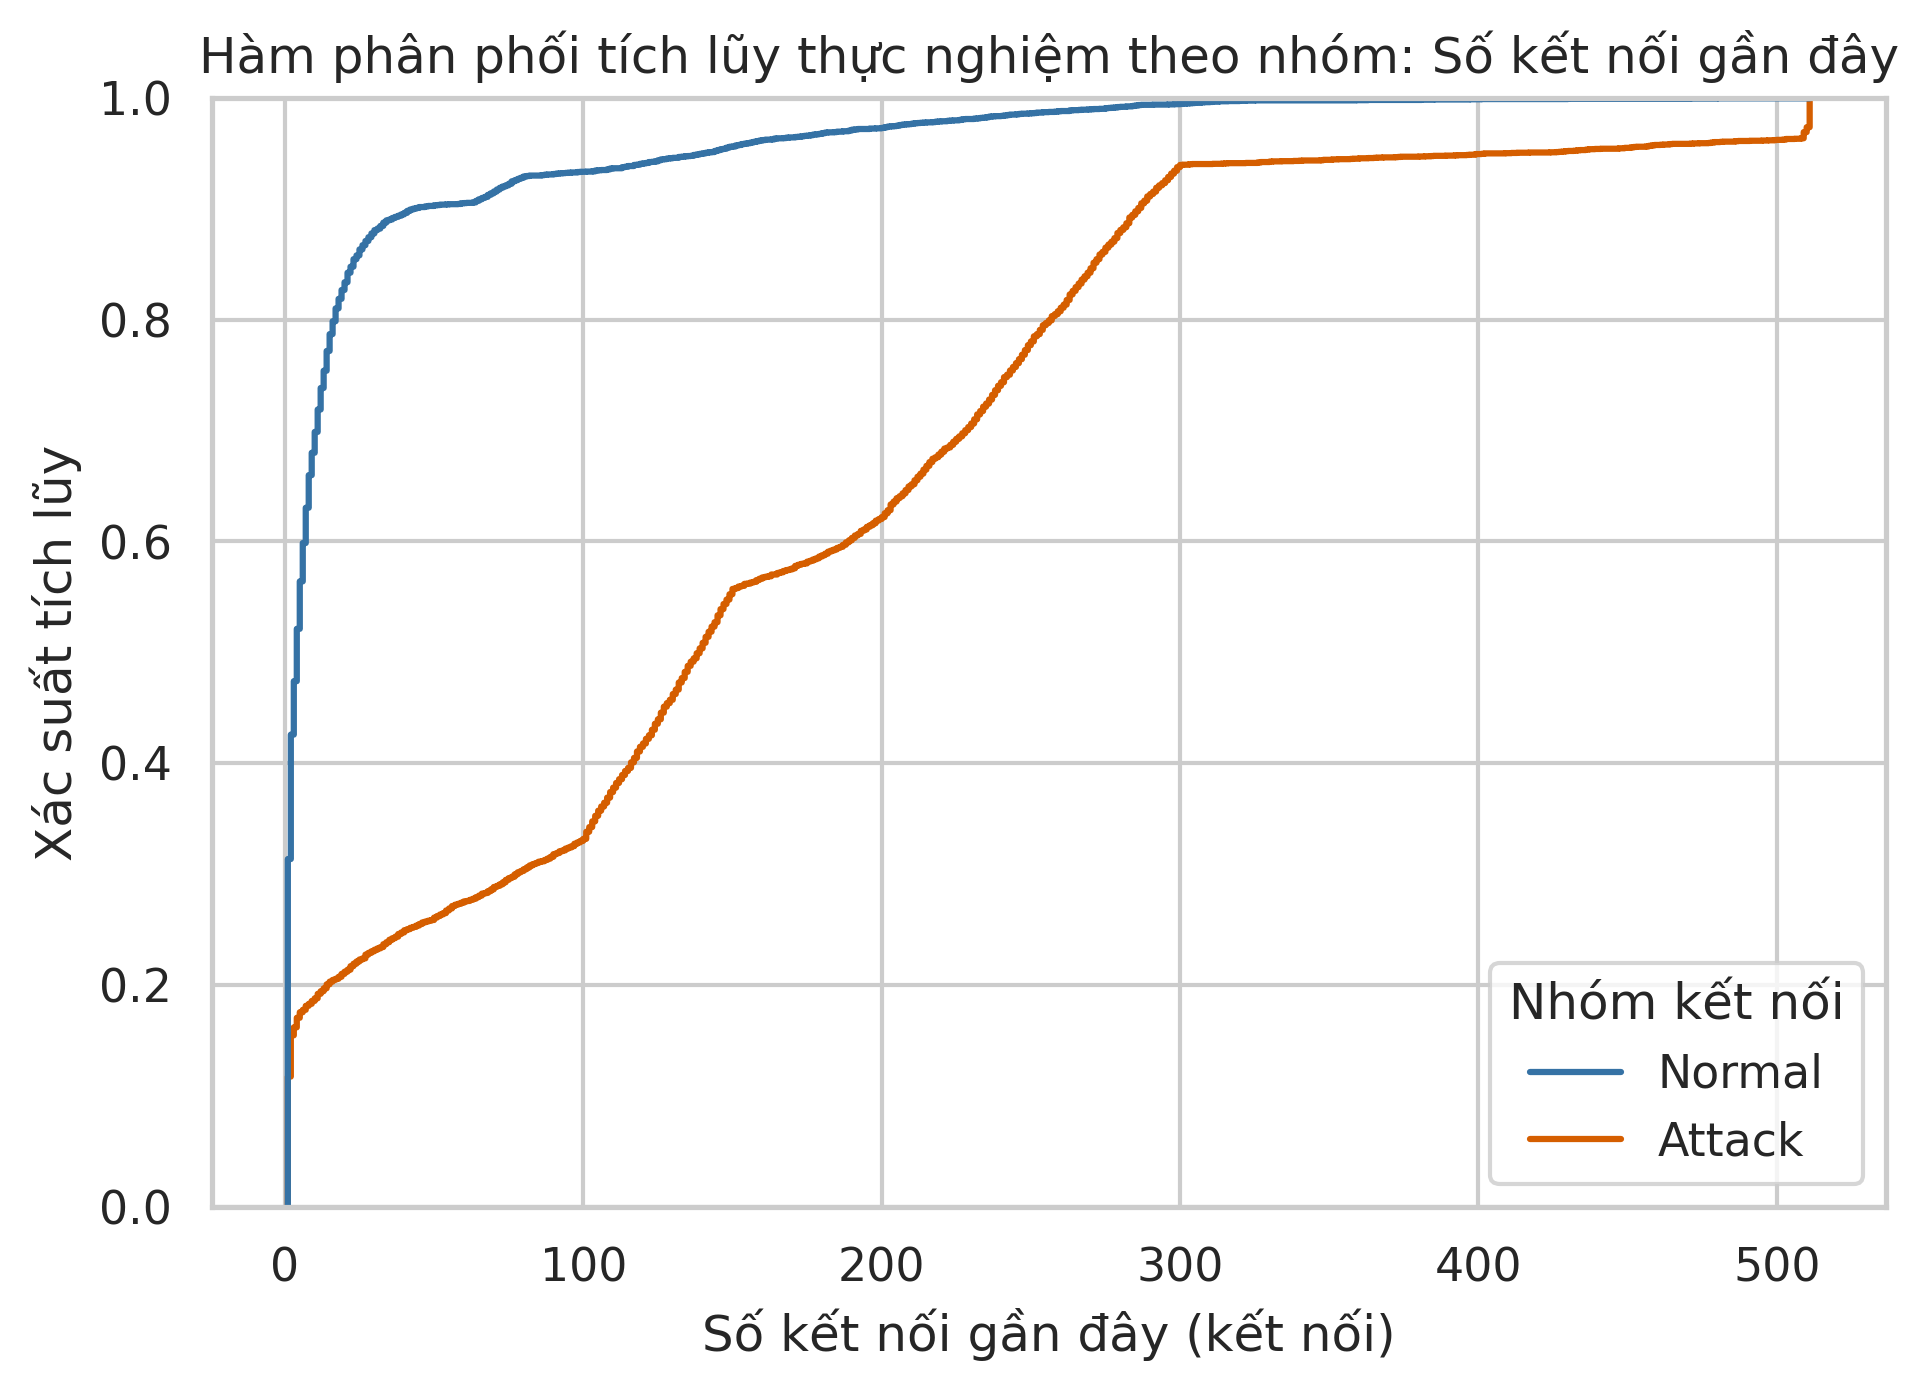

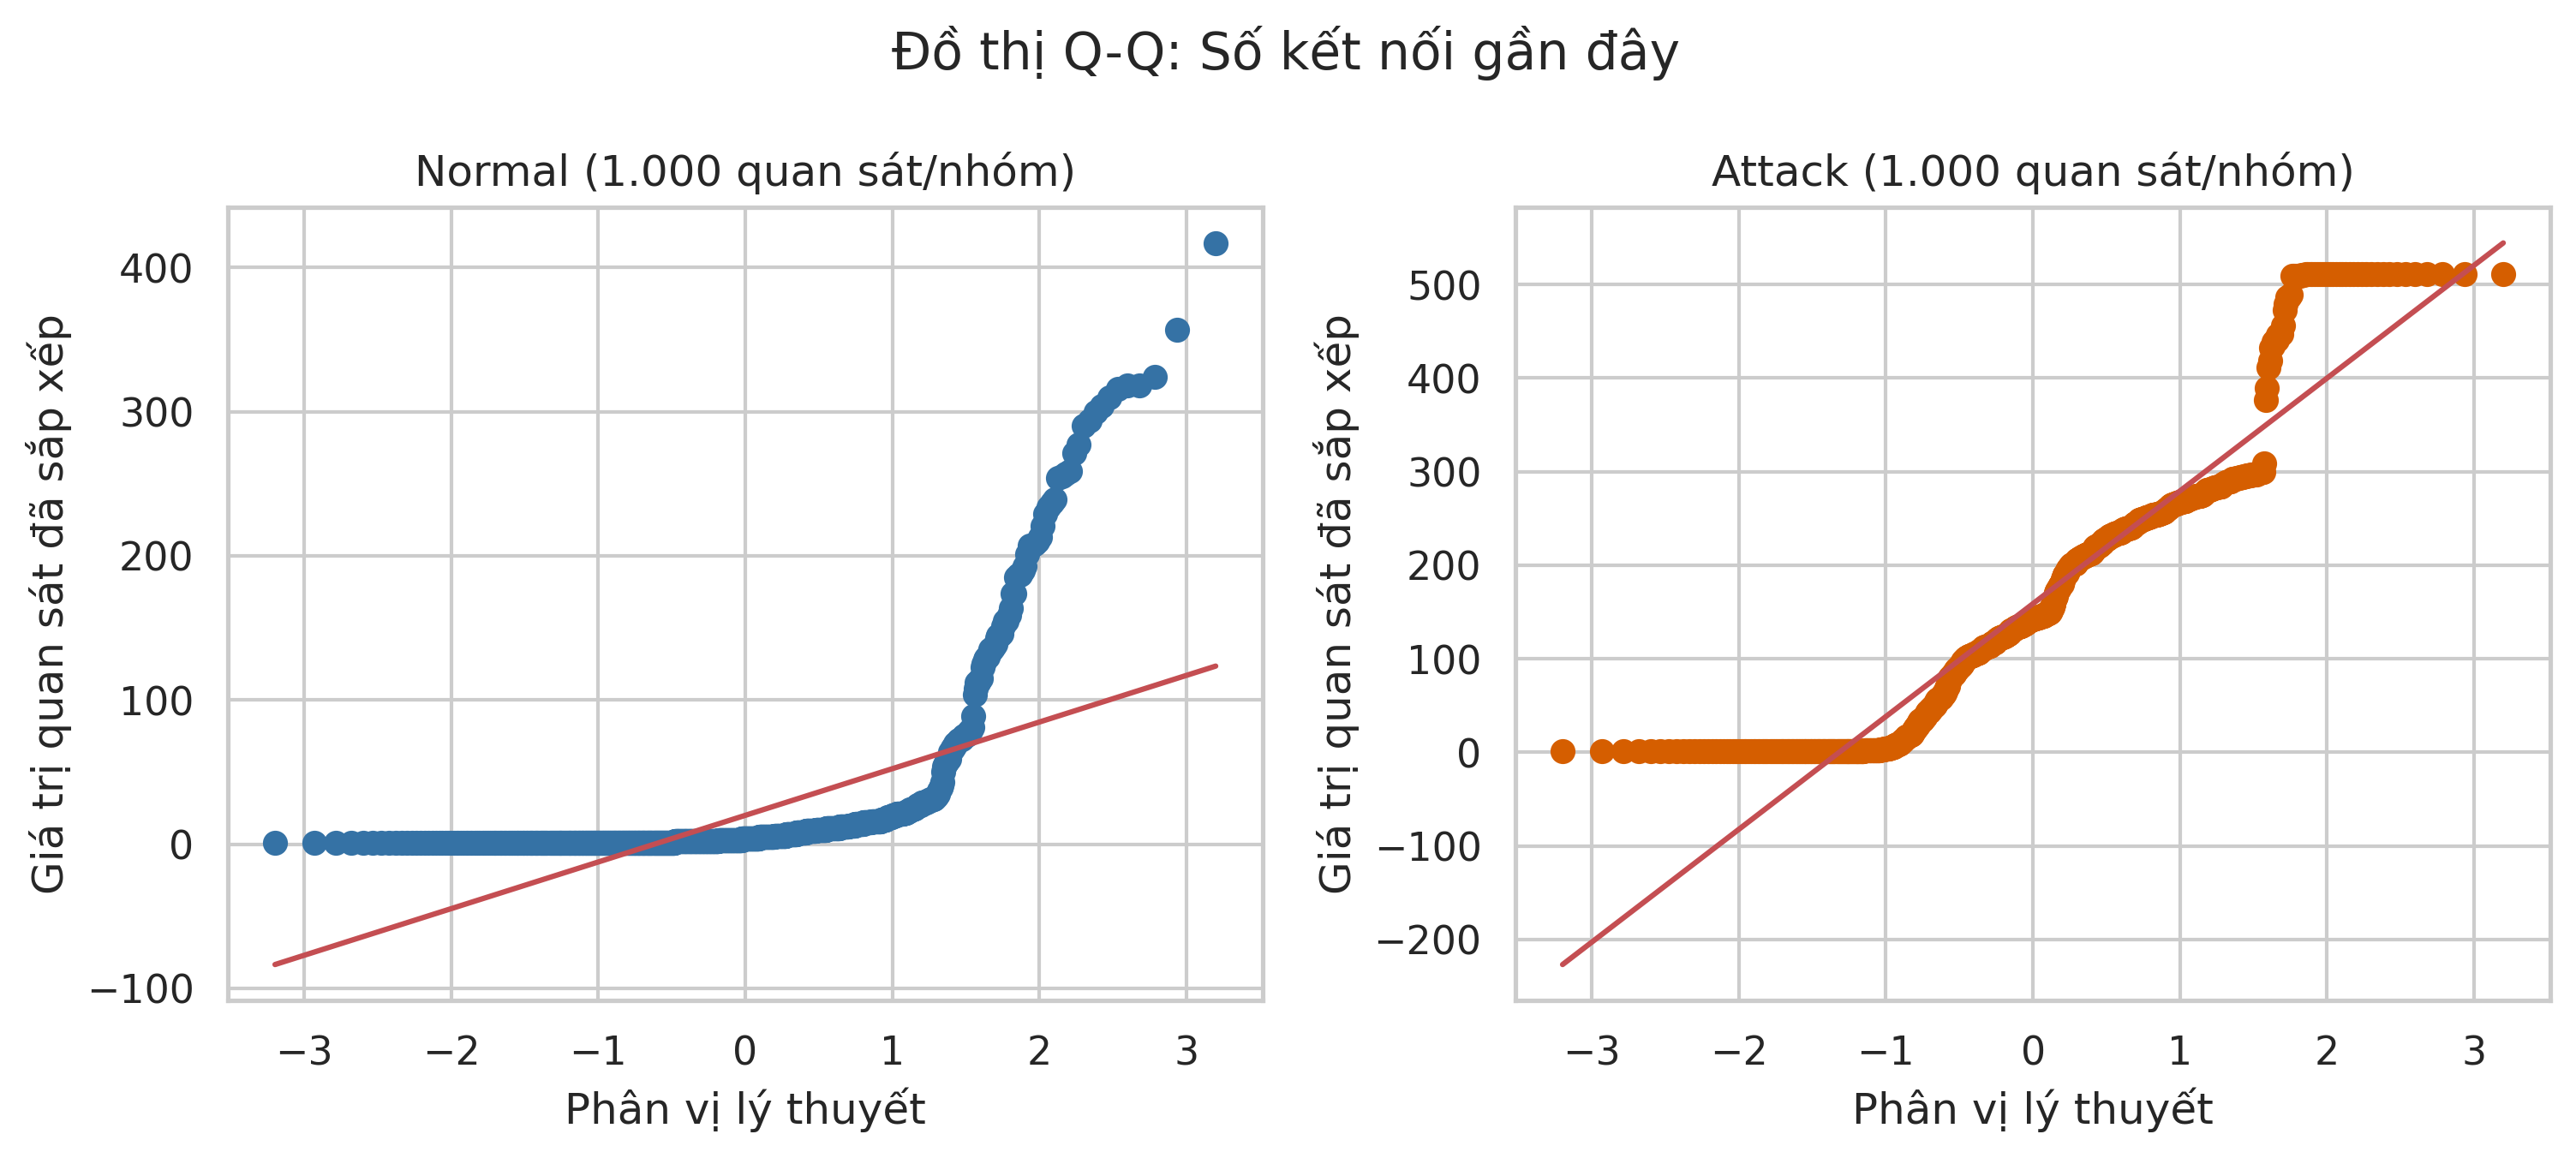

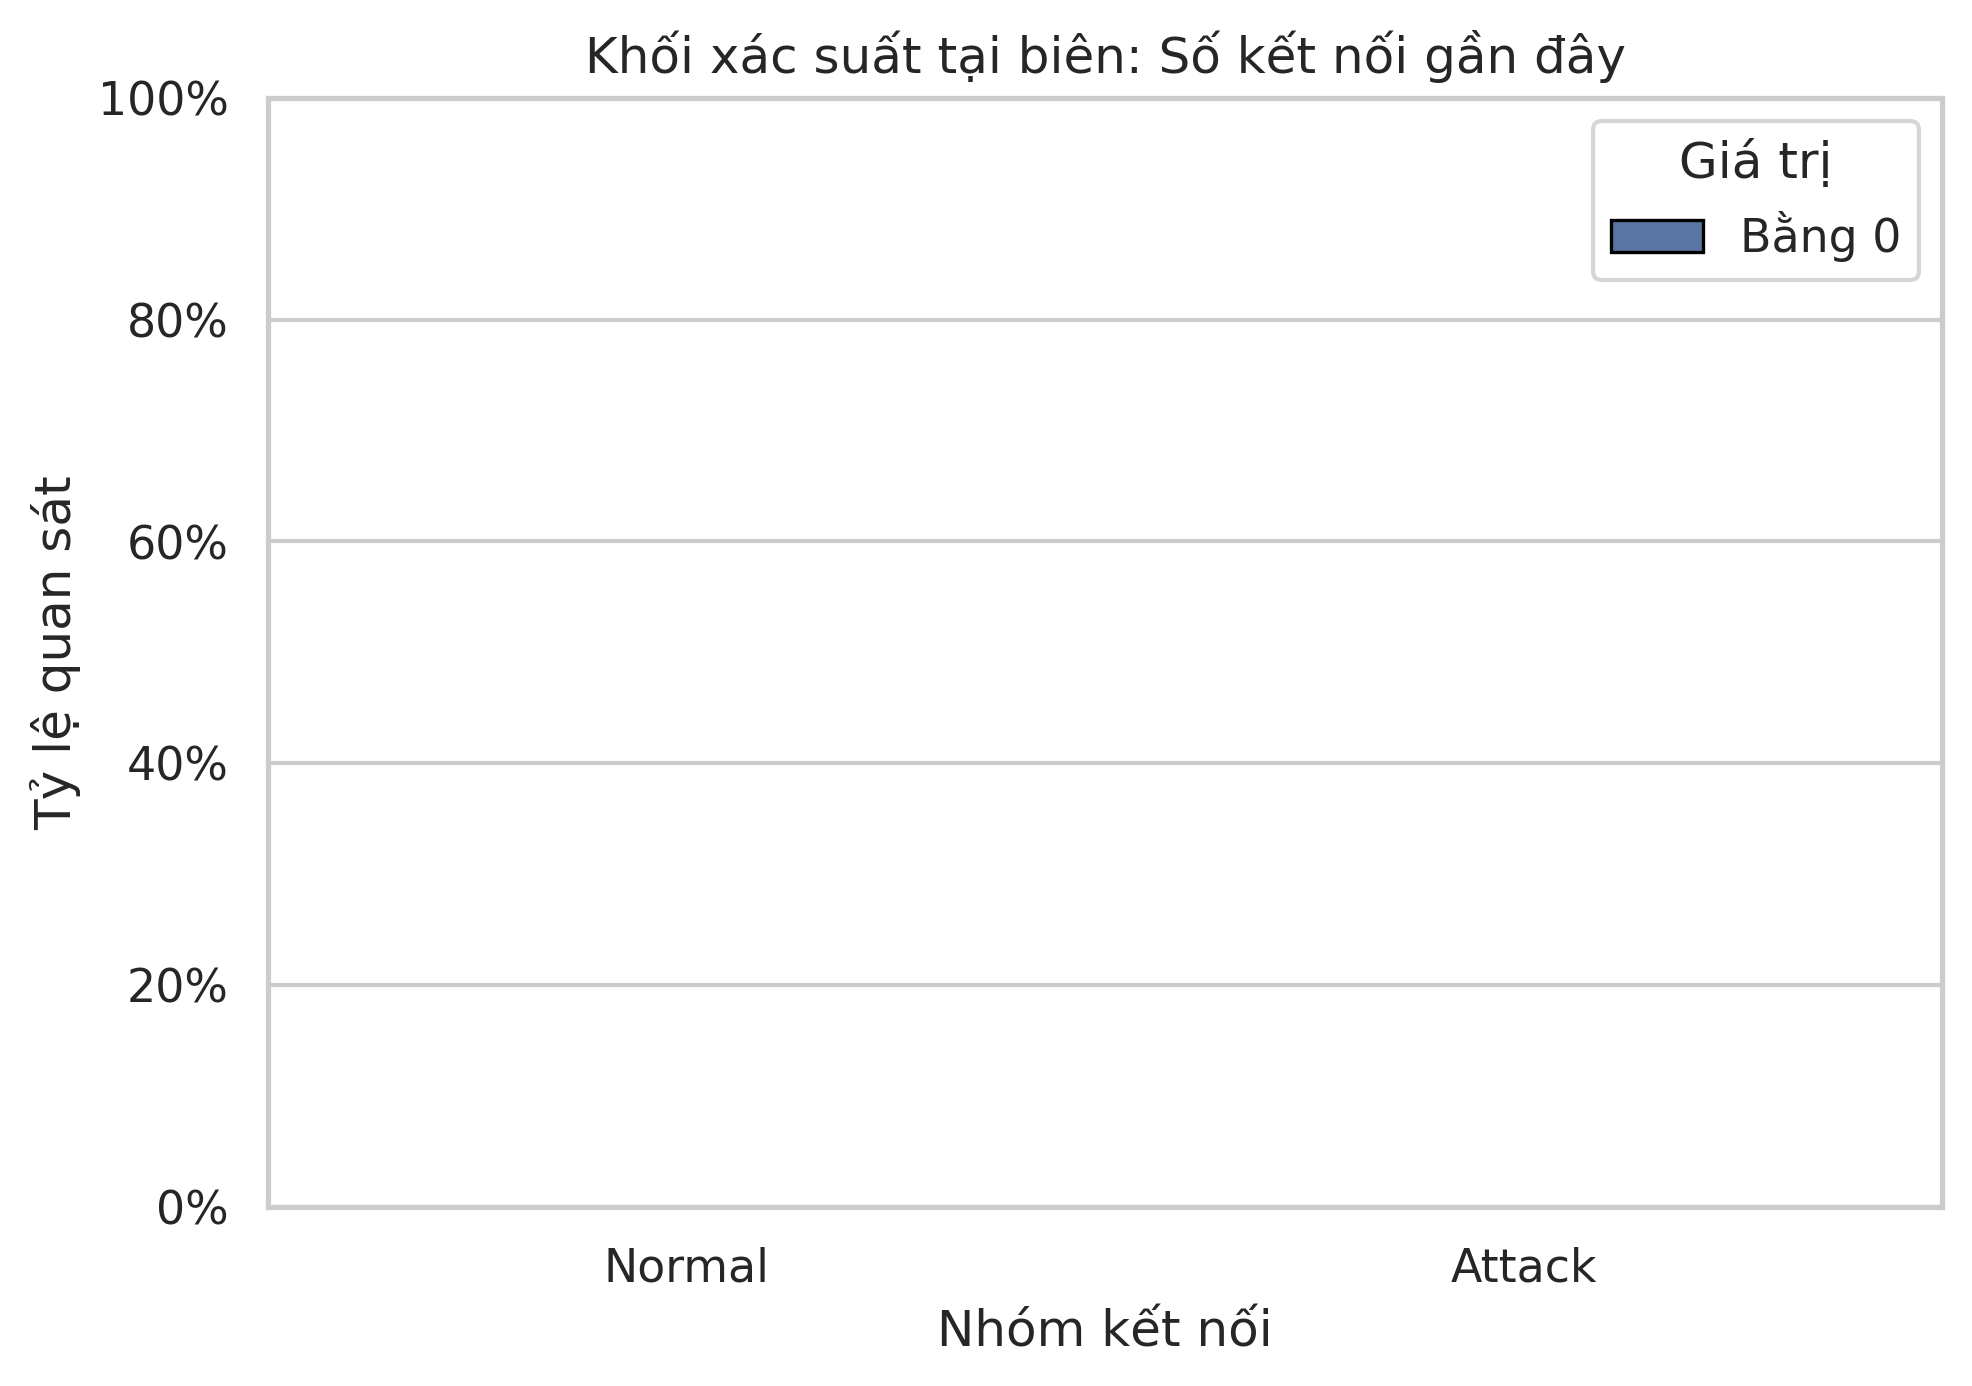

In [7]:
for rq, cfg in FEATURES.items():
    display(Markdown(f"### {rq} — `{cfg['feature']}`"))
    for name in ['01_boxplot.png','02_mean_ci95.png','03_ecdf.png','04_qq_plot.png','05_boundary_mass.png']:
        display(Image(filename=str(Path('figures') / cfg['feature'] / name), width=760))

### So sánh ba câu hỏi nghiên cứu

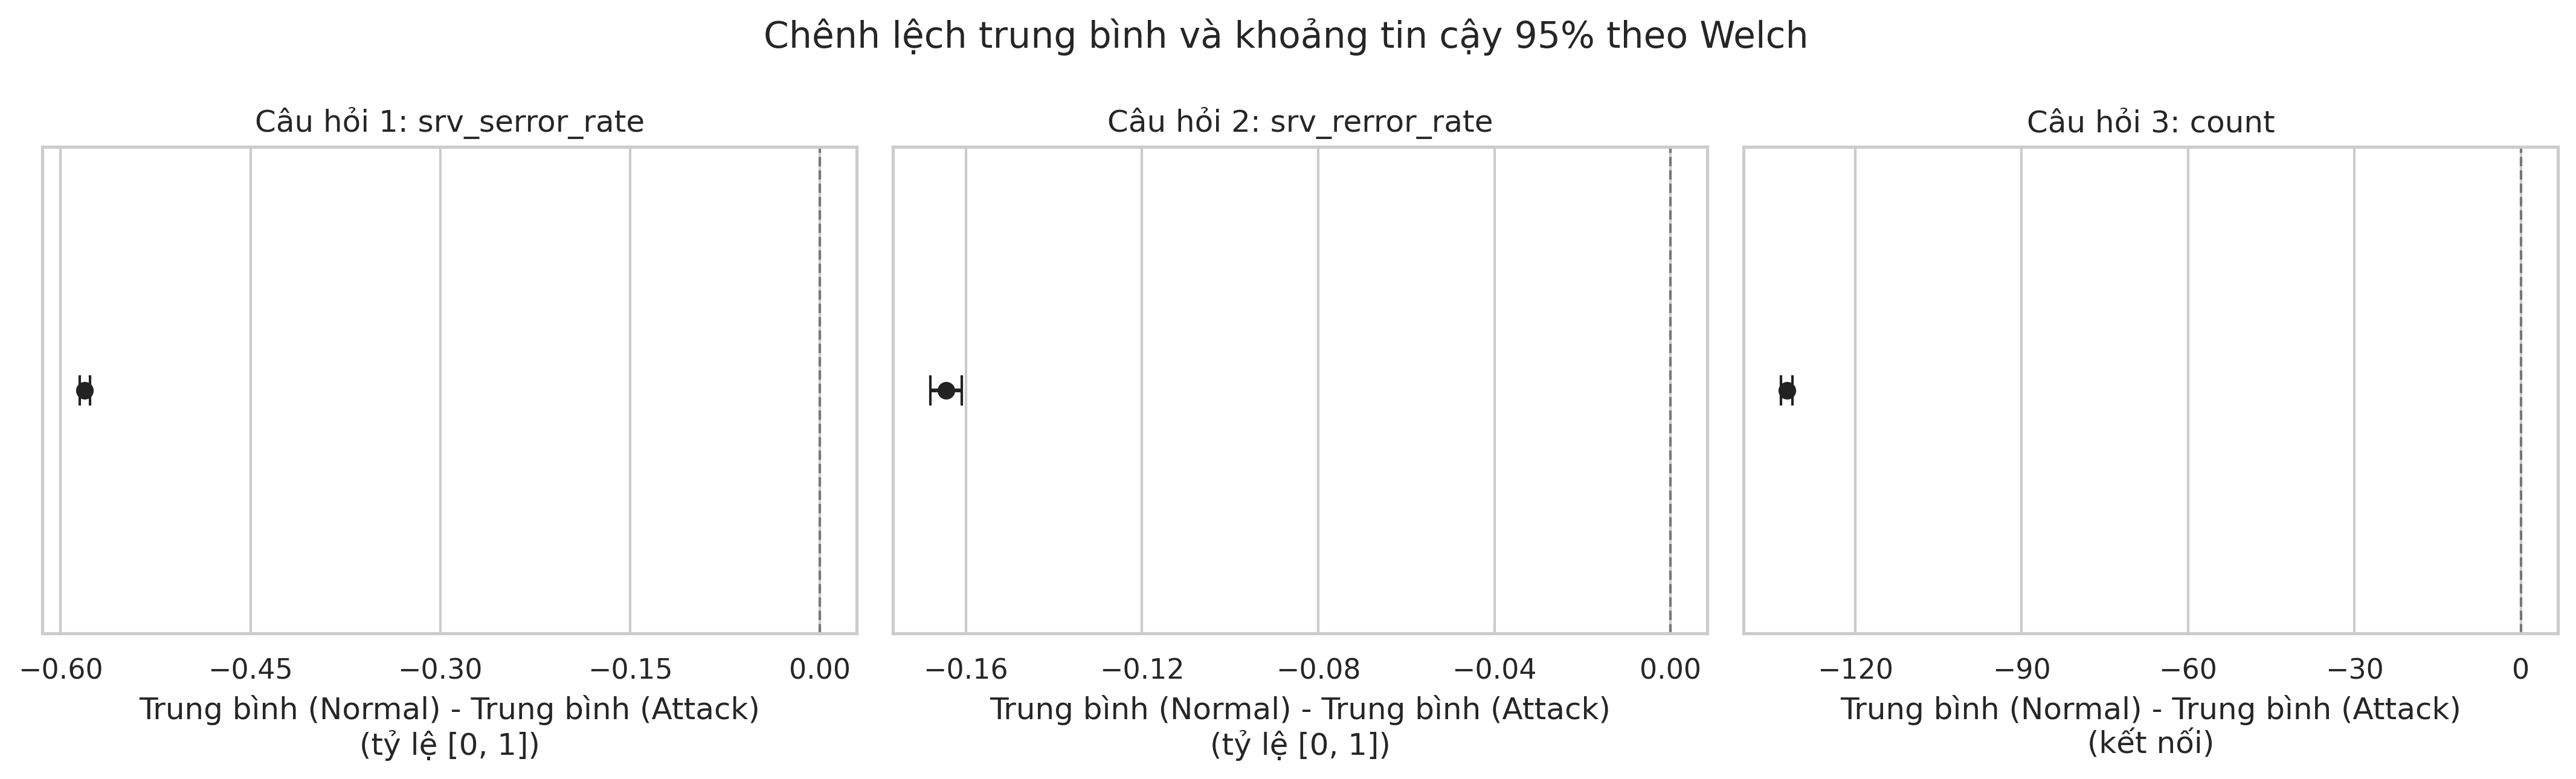

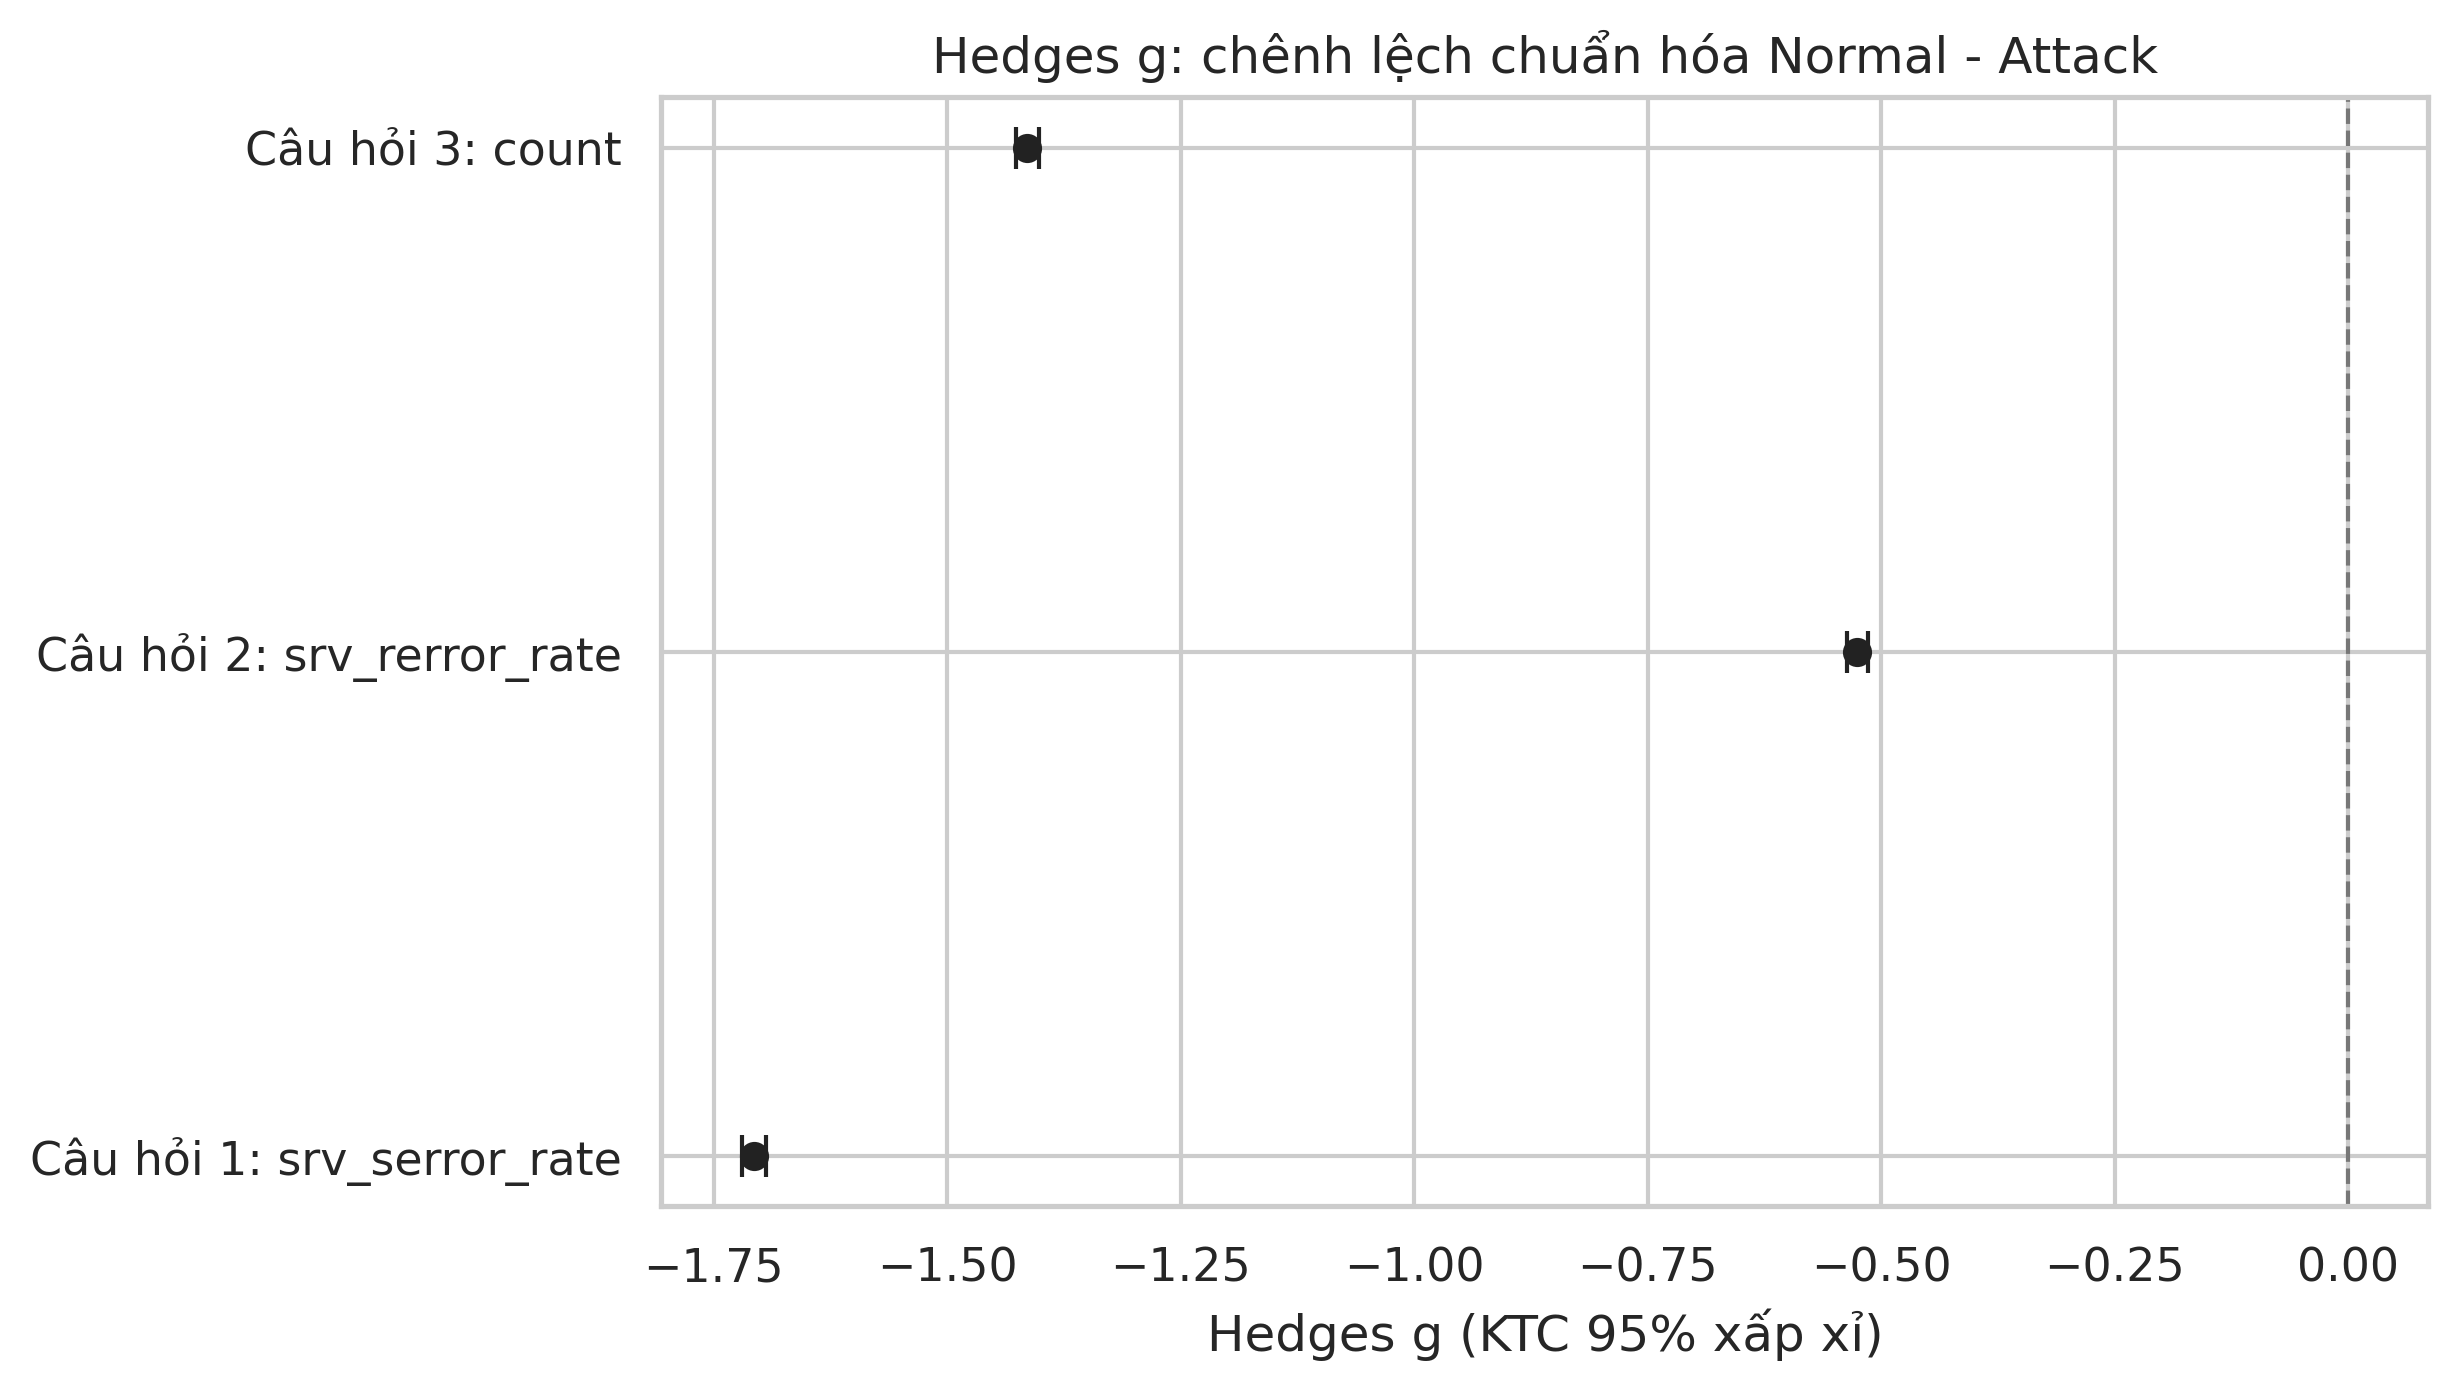

In [8]:
display(Markdown('### So sánh ba câu hỏi nghiên cứu'))
display(Image(filename='figures/comparison/mean_difference_forest.png', width=1000))
display(Image(filename='figures/comparison/effect_size_forest.png', width=760))

## Kết luận và giới hạn

Bảng dưới đây là kết quả chính cho ba RQ. Không xếp hạng khả năng dự đoán bằng p-value hay Hedges $g$: hiệu năng Machine Learning còn phụ thuộc tương tác, phi tuyến, dư thừa giữa biến và khả năng tổng quát hóa trên test set. Pearson và kiểm định hai mẫu trả lời các câu hỏi khác nhau nên việc chọn biến khác nhau không tạo mâu thuẫn.

In [9]:
display(tables['summary_results'])
display(Markdown(Path('results/interpretation.md').read_text(encoding='utf-8')))

,rq,feature,comparison,selected_test,n_normal,n_attack,mean_normal,mean_attack,mean_difference,standard_error,t_statistic,df,p_value,ci95_low,ci95_high,alpha,holm_adjusted_p_value,reject_h0_raw,reject_h0_holm,p_value_underflow,holm_p_underflow,p_value_display,holm_p_display,cohen_d,hedges_g,hedges_g_ci95_low_approx,hedges_g_ci95_high_approx,effect_ci_note,brown_forsythe_p_value,variance_ratio_max_min,method_warning,conclusion
0,RQ1,srv_serror_rate,Normal - Attack,Welch independent two-sample t-test (two-sided),67343,58630,0.012083,0.593072,-0.580988,0.002052,-283.156578,61805.395685,0.0,-0.585010,-0.576967,0.05,0.0,True,True,True,True,<1e-300,<1e-300,-1.706973,-1.706963,-1.719885,-1.694040,Normal approximation; descriptive pooled-SD ef...,0.0,32.174969,Biến tỷ lệ có khối xác suất tại biên; Welch su...,Bác bỏ H0 sau hiệu chỉnh Holm: trung bình Norm...
1,RQ2,srv_rerror_rate,Normal - Attack,Welch independent two-sample t-test (two-sided),67343,58630,0.044629,0.209114,-0.164485,0.001843,-89.230223,83489.743411,0.0,-0.168098,-0.160872,0.05,0.0,True,True,True,True,<1e-300,<1e-300,-0.525383,-0.525380,-0.536639,-0.514120,Normal approximation; descriptive pooled-SD ef...,0.0,3.999170,Biến tỷ lệ có khối xác suất tại biên; Welch su...,Bác bỏ H0 sau hiệu chỉnh Holm: trung bình Norm...
2,RQ3,count,Normal - Attack,Welch independent two-sample t-test (two-sided),67343,58630,22.517945,154.849991,-132.332046,0.554089,-238.828335,77661.212334,0.0,-133.418057,-131.246036,0.05,0.0,True,True,True,True,<1e-300,<1e-300,-1.414264,-1.414256,-1.426628,-1.401884,Normal approximation; descriptive pooled-SD ef...,0.0,5.296344,Biến đếm lệch và có ngoại lệ; dùng Welch nhờ c...,Bác bỏ H0 sau hiệu chỉnh Holm: trung bình Norm...


# Diễn giải kiểm định hai mẫu độc lập

Tập huấn luyện gốc được dùng cho suy luận; tập test không tham gia kiểm định. Chênh lệch được định nghĩa là mean(Normal) - mean(Attack).

## RQ1 — srv_serror_rate

Normal có trung bình 0.0120834 (n=67,343), còn Attack có trung bình 0.593072 (n=58,630). Chênh lệch Normal - Attack là -0.580988, CI 95% [-0.58501; -0.576967].
Welch t(61805.40) = -283.1566, p <1e-300; p hiệu chỉnh Holm <1e-300. Hedges g = -1.7070. Brown-Forsythe p <1e-300, tỷ số phương sai lớn/nhỏ=32.175.
Quyết định: bác bỏ H0 sau hiệu chỉnh Holm. Trong mẫu NSL-KDD, nhóm Attack có tỷ lệ lỗi SYN theo dịch vụ cao hơn rõ rệt, phù hợp với hành vi tạo kết nối thất bại/không hoàn tất bắt tay TCP thường gặp ở một số kiểu tấn công.
Phân tích độ nhạy: Mann-Whitney U (two-sided, asymptotic) có p <1e-300; Yuen-Welch t-test, 20% trimmed means có p <1e-300. Hai kết quả này hỗ trợ đánh giá độ bền nhưng không cùng estimand với trung bình gốc.
Cảnh báo: Biến tỷ lệ có khối xác suất tại biên; Welch suy luận về trung bình nhưng mô hình chuẩn chỉ là xấp xỉ. Không có metadata phiên/host nên không thể kiểm chứng đầy đủ tính độc lập; vì vậy kết quả là liên hệ thống kê, không phải quan hệ nhân quả.

## RQ2 — srv_rerror_rate

Normal có trung bình 0.0446291 (n=67,343), còn Attack có trung bình 0.209114 (n=58,630). Chênh lệch Normal - Attack là -0.164485, CI 95% [-0.168098; -0.160872].
Welch t(83489.74) = -89.2302, p <1e-300; p hiệu chỉnh Holm <1e-300. Hedges g = -0.5254. Brown-Forsythe p <1e-300, tỷ số phương sai lớn/nhỏ=3.999.
Quyết định: bác bỏ H0 sau hiệu chỉnh Holm. Trong mẫu NSL-KDD, nhóm Attack có tỷ lệ kết nối bị từ chối theo dịch vụ cao hơn; đặc trưng này phản ánh một khía cạnh khác của lỗi kết nối so với lỗi SYN.
Phân tích độ nhạy: Mann-Whitney U (two-sided, asymptotic) có p <1e-300; Yuen-Welch t-test, 20% trimmed means có p 4.905e-08. Hai kết quả này hỗ trợ đánh giá độ bền nhưng không cùng estimand với trung bình gốc.
Cảnh báo: Biến tỷ lệ có khối xác suất tại biên; Welch suy luận về trung bình nhưng mô hình chuẩn chỉ là xấp xỉ. Không có metadata phiên/host nên không thể kiểm chứng đầy đủ tính độc lập; vì vậy kết quả là liên hệ thống kê, không phải quan hệ nhân quả.

## RQ3 — count

Normal có trung bình 22.5179 (n=67,343), còn Attack có trung bình 154.85 (n=58,630). Chênh lệch Normal - Attack là -132.332, CI 95% [-133.418; -131.246].
Welch t(77661.21) = -238.8283, p <1e-300; p hiệu chỉnh Holm <1e-300. Hedges g = -1.4143. Brown-Forsythe p <1e-300, tỷ số phương sai lớn/nhỏ=5.296.
Quyết định: bác bỏ H0 sau hiệu chỉnh Holm. Nhóm Attack có số kết nối gần đây trung bình cao hơn, cho thấy cường độ/lặp lại kết nối là tín hiệu hành vi đáng chú ý trong bộ dữ liệu này.
Phân tích độ nhạy: Mann-Whitney U (two-sided, asymptotic) có p <1e-300; Yuen-Welch t-test, 20% trimmed means có p <1e-300. Hai kết quả này hỗ trợ đánh giá độ bền nhưng không cùng estimand với trung bình gốc.
Cảnh báo: Biến đếm lệch và có ngoại lệ; dùng Welch nhờ cỡ mẫu lớn, kèm phân tích độ nhạy robust/rank-based. Không có metadata phiên/host nên không thể kiểm chứng đầy đủ tính độc lập; vì vậy kết quả là liên hệ thống kê, không phải quan hệ nhân quả.

## Liên hệ với Pearson, ANOVA và Machine Learning

Pearson đo liên hệ tuyến tính giữa hai biến định lượng, còn Welch ở đây so sánh trung bình của một biến giữa nhãn Normal và Attack. Vì trả lời hai câu hỏi khác nhau, việc biến được chọn khác nhau không làm kết quả mâu thuẫn.
Trong kết quả Pearson hiện có, srv_serror_rate liên hệ rất mạnh với dst_host_srv_serror_rate (r≈0.9863); điều này cảnh báo tính dư thừa khi đưa đồng thời các biến tương quan cao vào mô hình.
Trong kết quả Pearson hiện có, srv_rerror_rate liên hệ rất mạnh với dst_host_srv_rerror_rate (r≈0.9702); điều này cảnh báo tính dư thừa khi đưa đồng thời các biến tương quan cao vào mô hình.
ANOVA hiện có so sánh count giữa năm nhóm Normal, DoS, Probe, R2L và U2R, cho Welch F(4, 405.49)=35907.45, p <1e-300. Kiểm định hai mẫu ở đây gộp bốn nhóm tấn công thành Attack; do đó nó trả lời một tương phản khác và chịu ảnh hưởng bởi tỷ trọng từng loại tấn công. Hai phân tích dùng cùng bản ghi nên không độc lập về thông tin.

Ý nghĩa thống kê không đồng nghĩa khả năng dự đoán tốt: p-value chịu ảnh hưởng mạnh của cỡ mẫu, không phản ánh trực tiếp độ phân tách từng quan sát, tương tác, phi tuyến hay hiệu năng ngoài mẫu. Các kết quả này hỗ trợ giải thích dữ liệu và chọn đặc trưng có hiểu biết, nhưng hiệu năng Machine Learning vẫn phải đánh giá trên test set bằng metric phù hợp.

Không diễn giải p-value hiển thị <1e-300 là bằng 0; đó là giới hạn biểu diễn số. Không kết luận nhãn tấn công gây ra thay đổi của đặc trưng.